# Customer Churn Prediction — Phase 2: Advanced Analysis & Feature Engineering

DEPI / IBM Data Science graduation project — Milestone 2

<div dir="rtl">

### النوت بوك دي بتعمل إيه؟

دي المرحلة التانية: **Advanced Analysis & Feature Engineering** (Milestone 2). بتبدأ من الملفات اللي طلعت من
المرحلة الأولى (`train.csv` و `validation.csv` و `test.csv` و `pipeline.pkl`)، ومابتغيّرش فيهم أي حاجة.

الخطوات:

1. نعمل **features جديدة** من الأعمدة الموجودة (FR-11).
2. نعمل **statistical tests** مع **effect sizes** لكل عمود (FR-09).
3. نشوف الـ **correlation** بين الـ features.
4. نحدّث الـ **pipeline** عشان يشمل الـ features الجديدة (FR-12).
5. نختار أهم الـ features بالـ **RFE**، ونقارن بالـ validation (FR-13).
6. نعمل **baseline** بالـ Logistic Regression، وده المرجع اللي أي موديل في المرحلة 3 لازم يغلبه.
7. نعمل **dashboard** تفاعلي (FR-10).
8. نحفظ كل حاجة للمرحلة 3.
9. نعمل **Evidently report** يقارن الـ train بالـ test، ونحفظ **reference dataset** للـ monitoring.
10. نسجّل الـ runs في MLflow.

**ممنوع في المرحلة دي:** Random Forest و XGBoost و SMOTE والـ tuning واختيار الـ threshold، واستخدام الـ test
في أي قرار. كل دول بتوع المرحلة 3. الـ test بيظهر هنا في حاجتين بس: بيتعمله transform ويتحفظ، وبيتقارن توزيعه
بالـ train في الـ Evidently report، ومفيش ولا قرار بيتاخد منه.

**عشان تشغّلها:** انسخ ملفات المرحلة الأولى في `data/input` (أو اكتب مكانها في `PHASE1_DIR` في خلية الـ
Settings)، واضغط **Run All**. هتاخد من 5 لـ 10 دقايق، وأطول خطوة هي الـ cross-validation في القسم 6.

</div>

## 1. Setup

In [1]:
%pip install -q --disable-pip-version-check -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings
os.environ["GIT_PYTHON_REFRESH"] = "quiet"      # MLflow: no warning when Git is not installed
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm notice from a library, not our code
import copy
import html
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import mlflow
from scipy.stats import chi2_contingency, pearsonr
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import f_classif, RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             confusion_matrix)
from sklearn_features.transformers import DataFrameSelector

sns.set_style("whitegrid")

<div dir="rtl">

**المكتبات الجديدة في المرحلة دي، وكلها من المنهج:**

| الأداة | بنستخدمها في إيه | الدرس |
|---|---|---|
| `chi2_contingency` (من `scipy.stats`) | اختبار Chi-Square بين عمود نصّي والـ churn | Statistics (Chi-Square Test). الكورس بيستخدم `scipy.stats` لـ `pearsonr` |
| `f_classif` | اختبار ANOVA F بين عمود رقمي والـ churn | Additional Topics، Feature Selection |
| `pearsonr` (من `scipy.stats`) | الـ correlation بين عمود رقمي والـ churn، عشان نرتّب كل الأعمدة على مقياس واحد | Statistics (Correlation) |
| `RFE` | اختيار أهم الـ features | Additional Topics، Feature Selection (Wrapper Method) |
| `LogisticRegression` | الموديل اللي جوه الـ RFE | Session 3 |
| `StratifiedKFold` | الـ cross-validation (5 folds، ونسبة الـ churn هي هي في كل fold) | Session 2 (KFold) و Additional Topics |

</div>

In [3]:
SEED = 42
DATASET_VERSION = "v2-phase2-features"

# Folders, relative to this notebook (it lives in phase2/notebooks/)
PHASE1_DIR = "../data/input"     # the Phase 1 outputs: train.csv, validation.csv, test.csv, pipeline.pkl
PHASE2_DIR = ".."                # the phase2 folder; outputs go to its data/, models/, results/, figures/, monitoring/


def phase1_file(name):
    return os.path.join(PHASE1_DIR, name)


def output_file(folder, name):
    path = os.path.join(PHASE2_DIR, folder)
    os.makedirs(path, exist_ok=True)
    return os.path.join(path, name)


phase1_files = ["train.csv", "validation.csv", "test.csv", "pipeline.pkl"]
missing = [name for name in phase1_files if not os.path.exists(phase1_file(name))]
assert not missing, f"Phase 1 files not found in {PHASE1_DIR}: {missing}. Copy them there, or change PHASE1_DIR."
print("Phase 1 files found in", PHASE1_DIR, ":", phase1_files)

Phase 1 files found in ../data/input : ['train.csv', 'validation.csv', 'test.csv', 'pipeline.pkl']


<div dir="rtl">

**Settings:** دي الخلية الوحيدة اللي ممكن تحتاج تغيّرها.

- `DATASET_VERSION`: اسم بنميّز بيه نسخة الداتا اللي فيها الـ features الجديدة، وده طلب FR-12. هنسجّله في
  MLflow، وهنكتبه في الـ Feature Engineering Summary.
- `PHASE1_DIR`: الفولدر اللي فيه ملفات المرحلة الأولى (`train.csv` و `validation.csv` و `test.csv` و
  `pipeline.pkl`). المسار نسبي من مكان النوت بوك (`phase2/notebooks`)، فبيشتغل على أي جهاز (Windows أو Mac)
  من غير ما تغيّر حاجة. لو الملفات في مكان تاني (مثلًا فولدر المرحلة الأولى في الـ repo)، اكتب مكانها هنا.
- `PHASE2_DIR`: فولدر المرحلة التانية. كل output بيتحفظ في الفولدر المناسب جواه: الداتا في `data/processed`،
  والـ pipeline والموديل في `models`، والجداول في `results`، والرسومات في `figures`، وملفات الـ monitoring في
  `monitoring`.
- `phase1_file` و `output_file`: functions صغيرة بتركّب المسار، و `output_file` بتعمل الفولدر لو مش موجود
  (`os.makedirs`).
- الـ `assert` بيتأكد إن الأربع ملفات موجودين، ولو فيه ملف ناقص بيوقف بإيرور واضح بيقول اسمه.

</div>

In [4]:
train_df = pd.read_csv(phase1_file("train.csv"))
val_df = pd.read_csv(phase1_file("validation.csv"))
test_df = pd.read_csv(phase1_file("test.csv"))

print("Train:", train_df.shape, "| Validation:", val_df.shape, "| Test:", test_df.shape)
print("Churn rate in train:", round(train_df["churn"].mean() * 100, 2), "%")

Train: (700000, 31) | Validation: (150000, 31) | Test: (150000, 31)
Churn rate in train: 9.92 %


<div dir="rtl">

بنقرا ملفات المرحلة الأولى. الداتا هنا **نضيفة ومقسومة**، فمش هننضف ولا هنقسم تاني.

</div>

In [5]:
target = "churn"

numeric_cols = ["age", "annual_income", "dependents", "tenure", "monthlycharges", "totalcharges",
                "num_services", "customer_satisfaction", "num_complaints", "num_service_calls",
                "late_payments", "avg_monthly_gb", "days_since_last_interaction", "credit_score"]

service_cols = ["has_phone_service", "has_internet_service", "has_online_security", "has_online_backup",
                "has_device_protection", "has_tech_support", "has_streaming_tv", "has_streaming_movies"]

binary_cols = ["senior_citizen", "paperless_billing"] + service_cols

category_cols = ["gender", "education", "marital_status", "contract", "payment_method"]

<div dir="rtl">

نفس قوائم الأعمدة اللي في المرحلة الأولى بالظبط.

</div>

## 2. Feature engineering

In [6]:
addon_cols = service_cols[2:]
skewed_cols = ["annual_income", "totalcharges", "avg_monthly_gb", "days_since_last_interaction"]


def add_features(data):
    data = data.copy()
    months = data["tenure"].replace(0, 1)            # a new customer (tenure 0) counts as 1 month

    # 1. tenure groups (the last group is open, so a new customer with tenure > 72 still gets a group)
    data["tenure_group"] = pd.cut(data["tenure"], bins=[-1, 6, 12, 24, 48, np.inf],
                                  labels=["0-6", "7-12", "13-24", "25-48", "49+"]).astype(str)

    # 2. number of active services, counted from the 8 has_* columns
    data["active_services"] = data[service_cols].sum(axis=1)

    # 3. internet add-ons without internet service (0/1)
    data["addons_without_internet"] = ((data["has_internet_service"] == 0) &
                                       (data[addon_cols].sum(axis=1) > 0)).astype(int)

    # 4-6. rates per month of tenure
    data["complaints_per_month"] = data["num_complaints"] / months
    data["calls_per_month"] = data["num_service_calls"] / months
    data["late_payments_per_month"] = data["late_payments"] / months

    # 7. billing ratio: current monthly charge / average monthly charge so far
    average_charge = (data["totalcharges"] / months).replace(0, np.nan)
    data["charge_ratio"] = data["monthlycharges"] / average_charge

    # 8. interaction: complaints of month-to-month customers
    data["m2m_x_complaints"] = (data["contract"] == "month_to_month").astype(int) * data["num_complaints"]

    # 9. log of the skewed columns (+1 because log(0) is undefined)
    for col in skewed_cols:
        data["log_" + col] = np.log(data[col] + 1)

    return data


train_fe = add_features(train_df)
val_fe = add_features(val_df)
test_fe = add_features(test_df)

print("Rows unchanged:", len(train_fe) == len(train_df), len(val_fe) == len(val_df), len(test_fe) == len(test_df))
print("Columns:", train_df.shape[1], "→", train_fe.shape[1])
new_cols = [c for c in train_fe.columns if c not in train_df.columns]
train_fe[new_cols].head()

Rows unchanged: True True True
Columns: 31 → 43


,tenure_group,active_services,addons_without_internet,complaints_per_month,calls_per_month,late_payments_per_month,charge_ratio,m2m_x_complaints,log_annual_income,log_totalcharges,log_avg_monthly_gb,log_days_since_last_interaction
0,25-48,1,0,0.030303,0.030303,0.030303,1.033116,0.0,10.667925,7.400278,0.000000,3.433987
1,0-6,3,1,0.000000,0.000000,1.000000,1.017483,0.0,11.034652,4.291418,0.000000,3.761200
2,0-6,6,0,1.000000,0.000000,1.000000,1.093525,0.0,11.260948,4.418961,3.300640,0.693147
3,49+,6,0,0.000000,0.036364,0.000000,1.022151,0.0,11.868989,8.206821,3.092405,1.098612
4,13-24,4,0,0.071429,0.142857,0.071429,1.400104,0.0,10.468894,6.512562,2.895359,2.079442


<div dir="rtl">

**الـ function دي (`add_features`) بتعمل 12 feature جديدة.** كل feature معمولة من أعمدة نفس العميل بس،
ومفيش ولا واحدة بتستخدم الـ `churn`، فمفيش leakage. ولأنها function، هنقدر نطبّقها على أي عميل جديد في
المرحلة 4 (FR-11).

| الـ feature | المعادلة | ليه |
|---|---|---|
| `tenure_group` | `pd.cut` بيقسم الـ tenure لـ 5 مجموعات: 0-6، 7-12، 13-24، 25-48، 49+ | سهل نشرح "العملاء الجداد" و"القدام" |
| `active_services` | مجموع أعمدة `has_*` | عدد الخدمات الحقيقي، لأن `num_services` مش متفق معاها (لاحظنا ده في المرحلة 1) |
| `addons_without_internet` | خدمة إنترنت من غير إنترنت | بتعلّم على الصفوف المتناقضة |
| `complaints_per_month` | الشكاوى ÷ الـ tenure | 3 شكاوى في شهرين أخطر من 3 في 5 سنين |
| `calls_per_month` | المكالمات ÷ الـ tenure | نفس الفكرة |
| `late_payments_per_month` | التأخير ÷ الـ tenure | نفس الفكرة |
| `charge_ratio` | الفاتورة الحالية ÷ متوسط الفاتورة | هل الفاتورة زادت؟ |
| `m2m_x_complaints` | الشكاوى لو العقد شهري، وصفر لو غير كده | **interaction:** الشكوى أخطر لو العميل يقدر يمشي أي شهر |
| `log_...` (4 أعمدة) | `np.log(x + 1)` | بنقلّل الـ skew (درس Numpy و Statistics) |

**الـ zero denominators (FR-11):** القسمة على الـ tenure، والـ tenure أقل قيمة فيه 1. بس عميل جديد ممكن
ييجي بـ tenure = 0، فـ `replace(0, 1)` بتعتبره شهر واحد. ولو `totalcharges` بصفر، الـ `charge_ratio` بيبقى
قيمة ناقصة، والـ pipeline بيملاها بالـ median. والـ `+1` في الـ log عشان `log(0)` مش معرّف.

**ليه آخر مجموعة `49+` مش `49-72`؟** أعلى tenure في الداتا 72، بس عميل جديد ممكن يكون عدّى الـ 72 شهر. لو آخر حد
في `pd.cut` كان 72، العميل ده مش هيقع في أي مجموعة، والـ pipeline هيملا المكان الفاضي بأكتر مجموعة متكررة، وهي
`0-6` (يعني هيعتبره عميل جديد، وده عكس الحقيقة)، أو هيطلع error في نسخ pandas الأقدم. عشان كده آخر حد `np.inf`.
في داتا التدريب `49+` هي هي `49-72` بالظبط، فالنتايج ماتغيّرتش.

**التأكد:** عدد الصفوف ماتغيّرش في التلات ملفات (`True True True`)، والأعمدة بقت 43 بدل 31.

</div>

In [7]:
train_fe[new_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
active_services,700000.0,4.328,1.582,0.000,3.000,4.000,5.000,8.000
addons_without_internet,700000.0,0.129,0.335,0.000,0.000,0.000,0.000,1.000
complaints_per_month,679094.0,0.121,0.327,0.000,0.000,0.014,0.083,7.000
calls_per_month,700000.0,0.301,0.666,0.000,0.022,0.080,0.250,12.000
late_payments_per_month,700000.0,0.069,0.227,0.000,0.000,0.000,0.033,5.000
charge_ratio,700000.0,1.069,0.170,0.608,0.960,1.018,1.083,2.962
m2m_x_complaints,679094.0,0.014,0.153,0.000,0.000,0.000,0.000,6.000
log_annual_income,679031.0,10.817,0.563,9.904,10.395,10.798,11.205,12.429
log_totalcharges,700000.0,6.937,1.231,2.851,6.186,7.133,7.872,9.580
log_avg_monthly_gb,665057.0,3.011,1.453,0.000,2.625,3.358,3.956,6.326


<div dir="rtl">

`describe()` على الـ features الجديدة. فيه قيم ناقصة في `complaints_per_month` و `m2m_x_complaints` و
`log_annual_income` و `log_avg_monthly_gb`، لأن الأعمدة الأصلية بتاعتهم كان فيها قيم ناقصة، والـ pipeline
هيملاها.

</div>

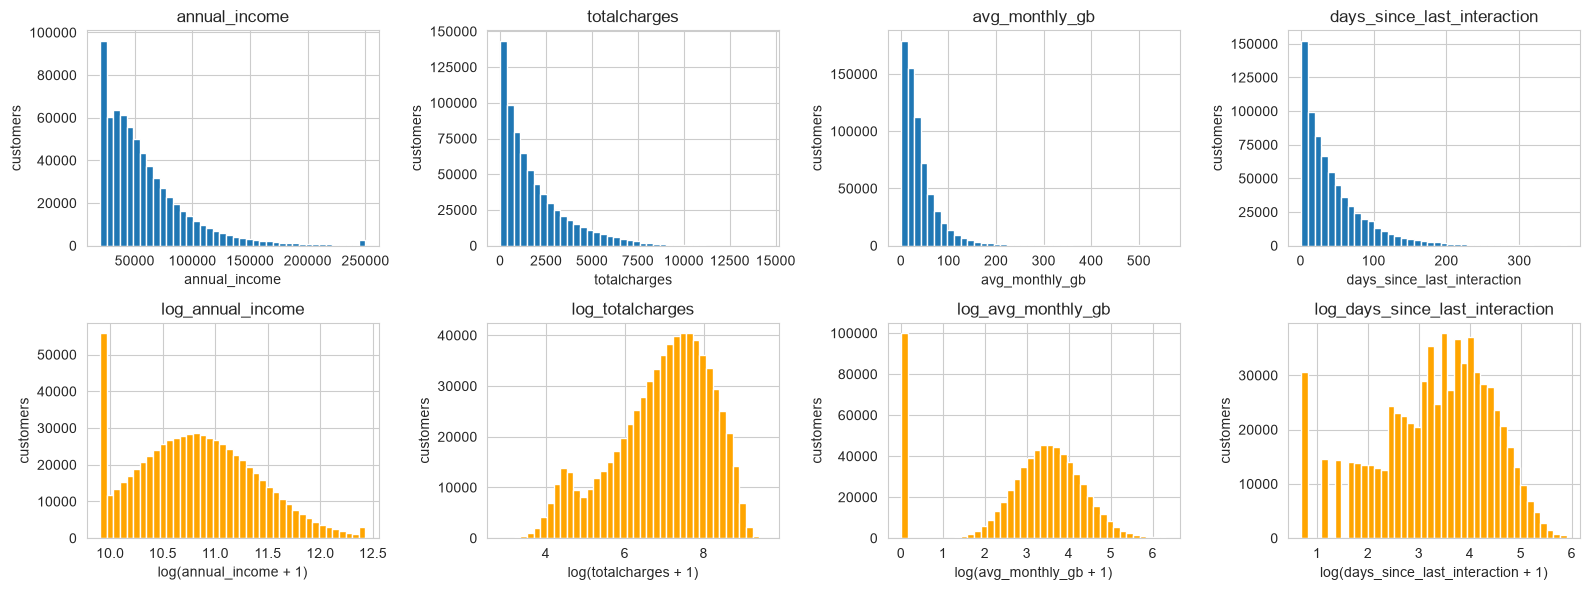

,skew before,skew after log
annual_income,1.84,0.28
totalcharges,1.51,-0.59
avg_monthly_gb,3.24,-1.02
days_since_last_interaction,1.95,-0.51


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, col in enumerate(skewed_cols):
    axes[0, i].hist(train_fe[col].dropna(), bins=40)
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel("customers")
    axes[1, i].hist(train_fe["log_" + col].dropna(), bins=40, color="orange")
    axes[1, i].set_title("log_" + col)
    axes[1, i].set_xlabel("log(" + col + " + 1)")
    axes[1, i].set_ylabel("customers")
plt.tight_layout()
plt.savefig(output_file("figures", "log_transform.png"))
plt.show()

skew_table = pd.DataFrame({"skew before": train_fe[skewed_cols].skew().values,
                           "skew after log": train_fe[["log_" + col for col in skewed_cols]].skew().values},
                          index=skewed_cols).round(2)
skew_table

<div dir="rtl">

**قبل وبعد الـ log (Matplotlib، subplots):** الصف الأزرق هو الأعمدة الأصلية، وكلها ذيلها طويل لليمين. الصف
البرتقالي بعد الـ log، والـ skew قلّ في الأربعة (من 1.5–3.2 لـ 0.3–1.0 بالقيمة المطلقة). الـ log بيشد الذيل
الطويل لجوه، فـ 3 منهم بقى عندهم ذيل خفيف ناحية الشمال بدل اليمين، وده عادي.

العمود العالي على الشمال في `log_avg_monthly_gb` هو العملاء اللي معندهمش إنترنت (0 GB). والعمود العالي في
`log_annual_income` هو أقل دخل في الداتا (20 ألف)، وده حد حطّه البرنامج اللي ولّد الداتا.

</div>

In [9]:
new_numeric = ["active_services", "complaints_per_month", "calls_per_month", "late_payments_per_month",
               "charge_ratio", "m2m_x_complaints"]
log_cols = ["log_" + col for col in skewed_cols]

feature_summary = pd.DataFrame([
    ["tenure_group", "category", "tenure cut into 0-6, 7-12, 13-24, 25-48, 49+ months",
     "churn risk changes with customer age; groups are easy to explain",
     "last group is open-ended, so tenure > 72 at prediction time still gets a group"],
    ["active_services", "number", "sum of the 8 has_* columns",
     "real number of services (num_services does not match the flags)", "—"],
    ["addons_without_internet", "0/1", "has_internet_service = 0 and at least one internet add-on = 1",
     "marks the inconsistent records found in Phase 1", "—"],
    ["complaints_per_month", "number", "num_complaints / tenure",
     "complaints relative to how long the customer has been with us",
     "tenure 0 counts as 1; missing when num_complaints is missing → training median in the pipeline"],
    ["calls_per_month", "number", "num_service_calls / tenure",
     "service calls relative to tenure", "tenure 0 counts as 1"],
    ["late_payments_per_month", "number", "late_payments / tenure",
     "payment problems relative to tenure", "tenure 0 counts as 1"],
    ["charge_ratio", "number", "monthlycharges / (totalcharges / tenure)",
     "is the customer paying more now than on average? (price increase)", "tenure 0 counts as 1; totalcharges 0 → missing → median"],
    ["m2m_x_complaints", "number", "num_complaints if contract is month_to_month, else 0",
     "complaints matter most when the customer can leave any month (interaction)",
     "missing when num_complaints is missing → training median in the pipeline"],
    ["log_annual_income", "number", "log(annual_income + 1)", "reduces right skew",
     "+1 avoids log(0); missing when annual_income is missing → training median in the pipeline"],
    ["log_totalcharges", "number", "log(totalcharges + 1)", "reduces right skew", "+1 avoids log(0)"],
    ["log_avg_monthly_gb", "number", "log(avg_monthly_gb + 1)", "reduces right skew (many zeros)",
     "+1 avoids log(0); missing when avg_monthly_gb is missing → training median in the pipeline"],
    ["log_days_since_last_interaction", "number", "log(days_since_last_interaction + 1)", "reduces right skew", "+1 avoids log(0)"],
], columns=["feature", "type", "formula", "why", "zero / missing handling"])

feature_summary["uses churn?"] = "no"
feature_summary["available before churn?"] = "yes — built only from columns of the same customer row"
feature_summary.to_csv(output_file("results", "feature_engineering_summary.csv"), index=False)
feature_summary

,feature,type,formula,why,zero / missing handling,uses churn?,available before churn?
0,tenure_group,category,"tenure cut into 0-6, 7-12, 13-24, 25-48, 49+ m...",churn risk changes with customer age; groups a...,"last group is open-ended, so tenure > 72 at pr...",no,yes — built only from columns of the same cust...
1,active_services,number,sum of the 8 has_* columns,real number of services (num_services does not...,—,no,yes — built only from columns of the same cust...
2,addons_without_internet,0/1,has_internet_service = 0 and at least one inte...,marks the inconsistent records found in Phase 1,—,no,yes — built only from columns of the same cust...
3,complaints_per_month,number,num_complaints / tenure,complaints relative to how long the customer h...,tenure 0 counts as 1; missing when num_complai...,no,yes — built only from columns of the same cust...
4,calls_per_month,number,num_service_calls / tenure,service calls relative to tenure,tenure 0 counts as 1,no,yes — built only from columns of the same cust...
5,late_payments_per_month,number,late_payments / tenure,payment problems relative to tenure,tenure 0 counts as 1,no,yes — built only from columns of the same cust...
6,charge_ratio,number,monthlycharges / (totalcharges / tenure),is the customer paying more now than on averag...,tenure 0 counts as 1; totalcharges 0 → missing...,no,yes — built only from columns of the same cust...
7,m2m_x_complaints,number,"num_complaints if contract is month_to_month, ...",complaints matter most when the customer can l...,missing when num_complaints is missing → train...,no,yes — built only from columns of the same cust...
8,log_annual_income,number,log(annual_income + 1),reduces right skew,+1 avoids log(0); missing when annual_income i...,no,yes — built only from columns of the same cust...
9,log_totalcharges,number,log(totalcharges + 1),reduces right skew,+1 avoids log(0),no,yes — built only from columns of the same cust...


<div dir="rtl">

**جدول الـ Feature Engineering Summary (FR-11):** لكل feature فيه المعادلة، وليه عملناها، وإزاي بنتعامل مع
الصفر والقيم الناقصة، ومراجعة الـ leakage (هل بتستخدم الـ churn؟ لأ. هل متاحة قبل ما العميل يمشي؟ أيوه).
اتحفظ في `feature_engineering_summary.csv`.

</div>

## 3. Exploratory analysis and statistical tests (train data only)

### 3a. What the data contains

In [10]:
# One row = one customer. The columns: the 31 from Phase 1 (customer_id, 29 features, churn) + the 12 Phase 2 features
phase1_columns = list(train_df.columns)
engineered = feature_summary["feature"].tolist()            # the 12 documented Phase 2 features
assert list(train_fe.columns) == phase1_columns + engineered, "columns differ from Phase 1 + documented features"

groups = {"customer_id": "identifier", target: "target"}
for group, cols in [("demographics", ["age", "gender", "annual_income", "education", "marital_status", "dependents",
                                      "senior_citizen", "credit_score"]),
                    ("account and billing", ["tenure", "contract", "payment_method", "paperless_billing",
                                             "monthlycharges", "totalcharges"]),
                    ("services", ["num_services"] + service_cols),
                    ("behaviour and usage", ["customer_satisfaction", "num_complaints", "num_service_calls",
                                             "late_payments", "avg_monthly_gb", "days_since_last_interaction"])]:
    groups.update({c: group for c in cols})


def value_range(col):
    values = train_fe[col].dropna()
    if col == "customer_id":
        return "one id per customer"
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 2:
        return f"{values.min():g} to {values.max():g}"
    order = (lambda v: int(str(v).split("-")[0].rstrip("+"))) if col == "tenure_group" else None   # 0-6 before 7-12
    return ", ".join(str(v) for v in sorted(values.unique(), key=order))


column_overview = pd.DataFrame({
    "column": train_fe.columns,
    "source": ["Phase 2 feature (add_features)" if c in engineered else "Phase 1 data" for c in train_fe.columns],
    "group": [groups.get(c, "engineered in Phase 2") for c in train_fe.columns],
    "dtype": [str(train_fe[c].dtype) for c in train_fe.columns],
    "unique values": [train_fe[c].nunique() for c in train_fe.columns],
    "values": [value_range(c) for c in train_fe.columns],
    "missing in train (%)": [round(train_fe[c].isnull().mean() * 100, 2) for c in train_fe.columns],
})
# Is a missing value itself related to churn? Churn rate of rows with and without a value, for each column with gaps
for c in train_fe.columns[train_fe.isnull().any()]:
    gap = train_fe[c].isnull()
    row = column_overview["column"] == c
    column_overview.loc[row, "churn % if missing"] = round(train_fe.loc[gap, target].mean() * 100, 2)
    column_overview.loc[row, "churn % if present"] = round(train_fe.loc[~gap, target].mean() * 100, 2)
column_overview.to_csv(output_file("results", "column_overview.csv"), index=False)

print("Customers (rows):", len(train_fe), "| columns:", train_fe.shape[1], "=", len(phase1_columns), "from Phase 1 +",
      len(engineered), "Phase 2 features")
print(column_overview.groupby(["source", "group"], sort=False).size().to_string())
column_overview

Customers (rows): 700000 | columns: 43 = 31 from Phase 1 + 12 Phase 2 features
source                          group                
Phase 1 data                    identifier                1
                                demographics              8
                                account and billing       6
                                services                  9
                                behaviour and usage       6
                                target                    1
Phase 2 feature (add_features)  engineered in Phase 2    12


,column,source,group,dtype,unique values,values,missing in train (%),churn % if missing,churn % if present
0,customer_id,Phase 1 data,identifier,str,700000,one id per customer,0.00,NaN,NaN
1,age,Phase 1 data,demographics,int64,73,18 to 90,0.00,NaN,NaN
2,gender,Phase 1 data,demographics,str,3,"female, male, other",0.00,NaN,NaN
3,annual_income,Phase 1 data,demographics,float64,608804,20000 to 250000,3.00,9.88,9.92
4,education,Phase 1 data,demographics,str,5,"bachelor, college, high_school, master, phd",0.00,NaN,NaN
5,marital_status,Phase 1 data,demographics,str,4,"divorced, married, single, widowed",0.00,NaN,NaN
6,dependents,Phase 1 data,demographics,int64,6,0 to 5,0.00,NaN,NaN
7,tenure,Phase 1 data,account and billing,int64,72,1 to 72,0.00,NaN,NaN
8,contract,Phase 1 data,account and billing,str,3,"month_to_month, one_year, two_year",0.00,NaN,NaN
9,payment_method,Phase 1 data,account and billing,str,4,"bank_transfer, credit_card, electronic_check, ...",0.00,NaN,NaN


<div dir="rtl">

### 3a. الداتا فيها إيه؟ (Exploratory Data Analysis)

قبل الاختبارات، لازم أي حد يفهم الداتا من غير ما يقرا الكود. الخلية دي بتعمل **جدول بكل عمود**
(`results/column_overview.csv`): العمود منين (المرحلة 1 ولا feature من المرحلة 2)، ونوعه، والمجموعة اللي تبعها، وقيمه،
ونسبة القيم الناقصة.

- **كل صف = عميل واحد.** عندنا 700,000 عميل في الـ train، و **43 عمود = 31 من المرحلة 1 + 12 feature من المرحلة 2**.
- الـ 29 feature الأصلية متقسمة: **demographics** (8: السن، النوع، الدخل، التعليم، الحالة الاجتماعية، المُعالين،
  كبار السن، الـ credit score)، و **account and billing** (6: الـ tenure، العقد، طريقة الدفع، الفاتورة الإلكترونية،
  الفاتورة الشهرية، والإجمالي)، و **services** (9: `num_services` و 8 أعمدة `has_*`)، و **behaviour and usage**
  (6: الرضا، الشكاوى، المكالمات، التأخير، الاستهلاك، أيام من آخر تواصل).
- **الـ target هو `churn`:** 1 = العميل مشي، 0 = فضل.
- السطر `assert` بيتأكد إن الأعمدة هي بالظبط أعمدة المرحلة 1 + الـ 12 اللي في `feature_engineering_summary.csv`،
  يعني **مفيش ولا عمود متألّف أو مش موثّق**.
- **هل غياب القيمة ليه علاقة بالـ churn؟** للأعمدة اللي فيها قيم ناقصة، الجدول بيقارن نسبة الـ churn لما القيمة ناقصة
  ولما موجودة: بين 9.68% و 10.18% مقابل حوالي 9.92%. يعني تقريبًا مفيش فرق، فملا القيم بالـ median من غير عمود
  إضافي (missing indicator) قرار معقول. (الـ 4 features الجديدة اللي فيها قيم ناقصة ورثتها من العمود الأصلي.)

</div>

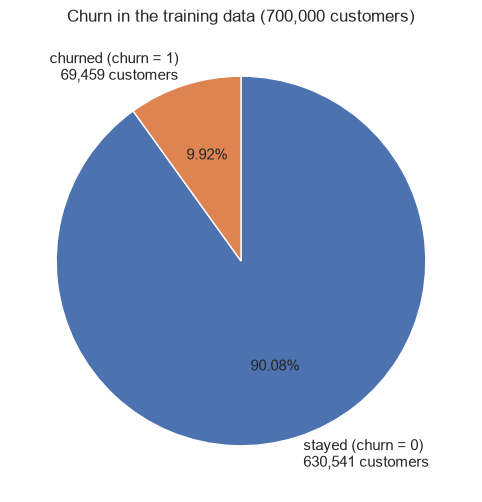

Stayed: 630541 | churned: 69459 | churn rate by split (%): {'train': np.float64(9.92), 'validation': np.float64(9.92), 'test': np.float64(9.92)}


In [11]:
counts = train_fe[target].value_counts().sort_index()          # index 0 = stayed, 1 = churned
split_rates = {name: round(data[target].mean() * 100, 2)
               for name, data in [("train", train_df), ("validation", val_df), ("test", test_df)]}

plt.figure(figsize=(6, 6))
plt.pie(counts.values, labels=[f"stayed (churn = 0)\n{counts[0]:,} customers", f"churned (churn = 1)\n{counts[1]:,} customers"],
        autopct="%1.2f%%", startangle=90, counterclock=False, colors=["#4C72B0", "#DD8452"],
        wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 11})
plt.title(f"Churn in the training data ({len(train_fe):,} customers)")
plt.savefig(output_file("figures", "churn_distribution.png"), bbox_inches="tight")
plt.show()
print("Stayed:", counts[0], "| churned:", counts[1], "| churn rate by split (%):", split_rates)

<div dir="rtl">

**توزيع الـ target (pie chart):** من 700,000 عميل في الـ train، **69,459 مشيوا (9.92%)** و **630,541 فضلوا (90.08%)**.
ونفس النسبة 9.92% في الـ validation والـ test، لأن المرحلة 1 قسمت بـ stratify على الـ churn.

**ليه ده مهم؟** الداتا **imbalanced**: موديل بيقول "محدش هيمشي" على طول هياخد accuracy 90% وهو ملوش فايدة. عشان كده
بنقيس بالـ ROC-AUC والـ PR-AUC، والتعامل مع الـ imbalance (SMOTE أو class weights) شغل المرحلة 3.

</div>

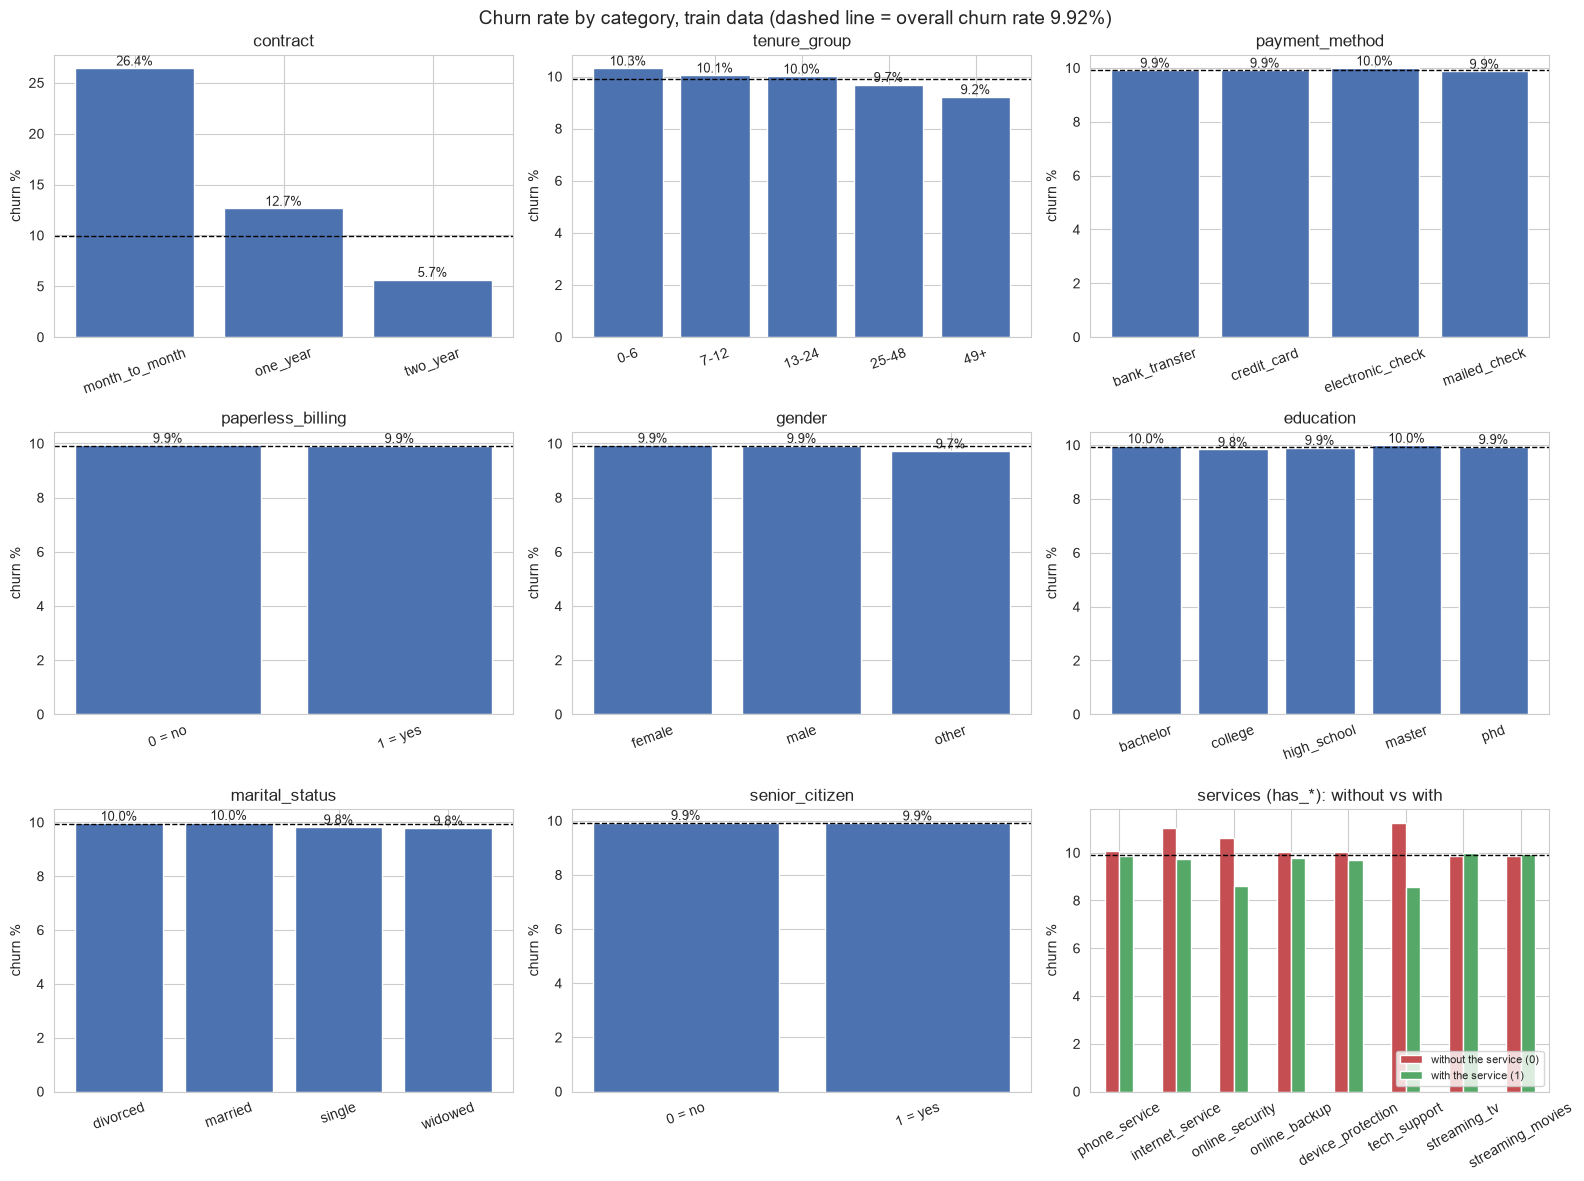

Gap between the highest and the lowest churn % inside each feature (percentage points):
feature
contract                 20.78
has_tech_support          2.69
has_online_security       2.02
has_internet_service      1.33
tenure_group              1.10
has_device_protection     0.30
has_online_backup         0.28
gender                    0.21
marital_status            0.20
has_phone_service         0.18
education                 0.15
has_streaming_tv          0.12
payment_method            0.12
has_streaming_movies      0.09
senior_citizen            0.02
paperless_billing         0.01


In [12]:
overall_rate = train_fe[target].mean() * 100
category_features = ["contract", "tenure_group", "payment_method", "paperless_billing", "gender", "education",
                     "marital_status", "senior_citizen"]
tenure_order = ["0-6", "7-12", "13-24", "25-48", "49+"]

rows = []
for col in category_features + service_cols:
    for value, part in train_fe.groupby(col)[target]:
        rows.append({"feature": col, "value": str(value), "customers": len(part), "churned": int(part.sum()),
                     "churn %": round(part.mean() * 100, 2)})
churn_by_group = pd.DataFrame(rows)
churn_by_group.to_csv(output_file("results", "churn_rate_by_group.csv"), index=False)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, category_features):
    part = churn_by_group[churn_by_group["feature"] == col].set_index("value")
    if col == "tenure_group":
        part = part.loc[tenure_order]
    names = ["0 = no", "1 = yes"] if list(part.index) == ["0", "1"] else list(part.index)
    ax.bar(names, part["churn %"], color="#4C72B0")
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
    for x, rate in enumerate(part["churn %"]):
        ax.text(x, rate, f"{rate:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(col)
    ax.set_ylabel("churn %")
    ax.tick_params(axis="x", rotation=20)
services = churn_by_group[churn_by_group["feature"].isin(service_cols)].pivot(index="feature", columns="value",
                                                                              values="churn %").loc[service_cols]
services.index = [c.replace("has_", "") for c in services.index]
services.columns = ["without the service (0)", "with the service (1)"]
services.plot(kind="bar", ax=axes.flat[8], color=["#C44E52", "#55A868"])
axes.flat[8].axhline(overall_rate, color="black", linestyle="--", linewidth=1)
axes.flat[8].legend(fontsize=8, loc="lower right")
axes.flat[8].set_title("services (has_*): without vs with")
axes.flat[8].set_ylabel("churn %")
axes.flat[8].tick_params(axis="x", rotation=30)
fig.suptitle(f"Churn rate by category, train data (dashed line = overall churn rate {overall_rate:.2f}%)", fontsize=14)
plt.tight_layout()
plt.savefig(output_file("figures", "churn_rate_by_category.png"), bbox_inches="tight")
plt.show()

spread = churn_by_group.groupby("feature")["churn %"].agg(lambda rates: rates.max() - rates.min())
spread = spread.sort_values(ascending=False).round(2)
print("Gap between the highest and the lowest churn % inside each feature (percentage points):")
print(spread.to_string())

<div dir="rtl">

**نسبة الـ churn لكل فئة:** لكل عمود فئوي، نسبة الـ churn في كل فئة، والخط المتقطع هو النسبة العامة (9.92%).
الأرقام في `results/churn_rate_by_group.csv` (فيها عدد العملاء واللي مشيوا لكل فئة).

- **العقد هو الفرق الكبير الوحيد:** الشهري 26.4%، السنة 12.7%، السنتين 5.7% (فرق 20.7 نقطة).
- **الخدمات:** اللي عندهم **tech support** بيمشوا أقل (8.6% مقابل 11.3%)، وكمان **online security** (8.6% مقابل 10.6%)،
  واللي **معندهمش إنترنت** بيمشوا أكتر شوية (11.1% مقابل 9.7%).
- **`tenure_group`:** بيقل شوية مع الوقت، من 10.3% لـ 9.2%.
- **الباقي كله تقريبًا مسطّح** (الفرق جوه العمود نقطة مئوية واحدة أو أقل): طريقة الدفع، الفاتورة الإلكترونية، النوع،
  التعليم، الحالة الاجتماعية، كبار السن، والتليفون والـ backup والـ device protection والـ streaming.

السطور اللي تحت الرسمة بتطبع الفرق بين أعلى وأقل فئة جوه كل عمود، وده نفس الكلام بالأرقام. ده متّسق مع الـ Cramér's V
اللي جاي في 3b.

</div>

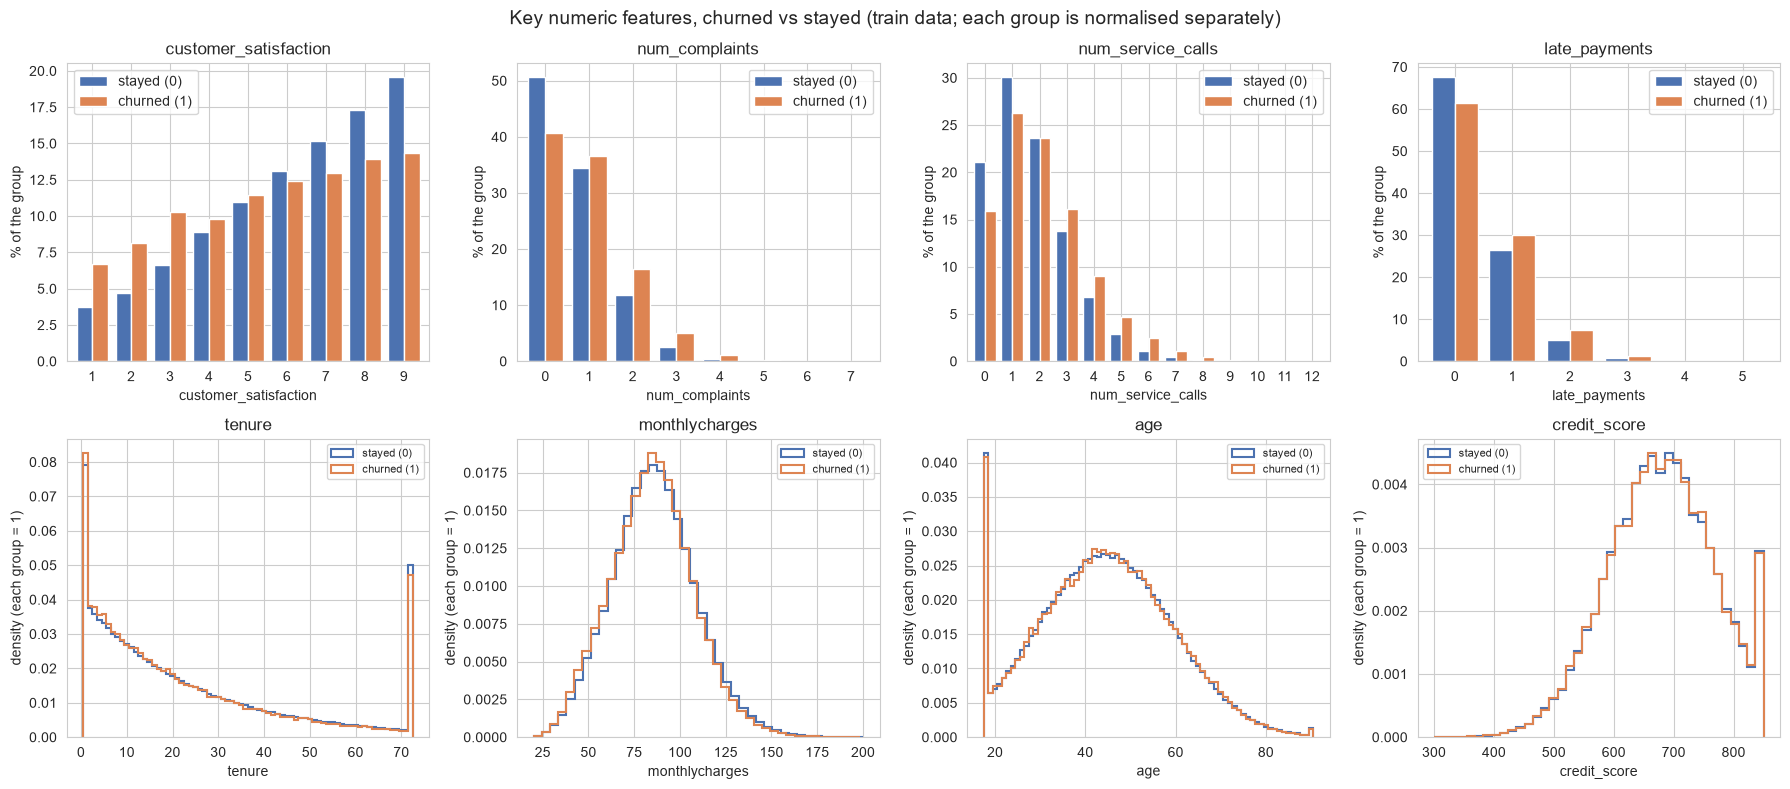

,stayed (0),churned (1)
customer_satisfaction,6.22,5.56
num_complaints,0.68,0.90
num_service_calls,1.72,2.10
late_payments,0.39,0.49
tenure,22.48,21.70
monthlycharges,86.10,84.84
age,44.71,44.77
credit_score,678.47,678.45


In [13]:
count_features = ["customer_satisfaction", "num_complaints", "num_service_calls", "late_payments"]
continuous_features = ["tenure", "monthlycharges", "age", "credit_score"]
group_colors = {0: "#4C72B0", 1: "#DD8452"}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes[0], count_features):
    shares = train_fe.groupby(target)[col].value_counts(normalize=True).mul(100).unstack(0).sort_index()
    shares.columns = ["stayed (0)", "churned (1)"]
    shares.index = shares.index.astype(int)
    shares.plot(kind="bar", ax=ax, color=[group_colors[0], group_colors[1]], width=0.8)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("% of the group")
    ax.tick_params(axis="x", rotation=0)
for ax, col in zip(axes[1], continuous_features):
    values = train_fe[col].dropna()
    whole = (values % 1 == 0).all() and values.max() - values.min() <= 100     # whole numbers: one bin per value
    bins = np.arange(values.min(), values.max() + 2) - 0.5 if whole else 40
    for value, label in [(0, "stayed (0)"), (1, "churned (1)")]:
        ax.hist(train_fe.loc[train_fe[target] == value, col].dropna(), bins=bins, histtype="step", linewidth=1.5,
                density=True, color=group_colors[value], label=label)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("density (each group = 1)")
    ax.legend(fontsize=8)
fig.suptitle("Key numeric features, churned vs stayed (train data; each group is normalised separately)", fontsize=14)
plt.tight_layout()
plt.savefig(output_file("figures", "numeric_distributions_by_churn.png"), bbox_inches="tight")
plt.show()

means = train_fe.groupby(target)[count_features + continuous_features].mean().T.round(2)
means.columns = ["stayed (0)", "churned (1)"]
means

<div dir="rtl">

**الأعمدة الرقمية: اللي مشيوا مقابل اللي فضلوا.** كل مجموعة متحسبة لوحدها (100% لكل مجموعة)، عشان المقارنة تبقى عادلة
مع إن اللي مشيوا 10% بس.

- **فوق (أعداد):** اللي مشيوا عندهم **رضا أقل** (نسبتهم أعلى في الدرجات من 1 لـ 5)، و **شكاوى ومكالمات وتأخير أكتر**.
  المتوسطات في الجدول: الرضا 5.56 مقابل 6.22، الشكاوى 0.90 مقابل 0.68، المكالمات 2.10 مقابل 1.72، التأخير 0.49
  مقابل 0.39.
- **تحت (مستمرة):** الـ tenure والفاتورة الشهرية والسن والـ credit score **الخطين تقريبًا فوق بعض**، يعني
  التوزيع هو هو للمجموعتين. (القمم عند tenure = 72 و credit score = 850 و السن 18 حدود في الداتا نفسها.)

ده نفس اللي هتقوله الاختبارات: الفرق في السلوك (الرضا والشكاوى والمكالمات)، مش في الـ demographics ولا الفاتورة.

</div>

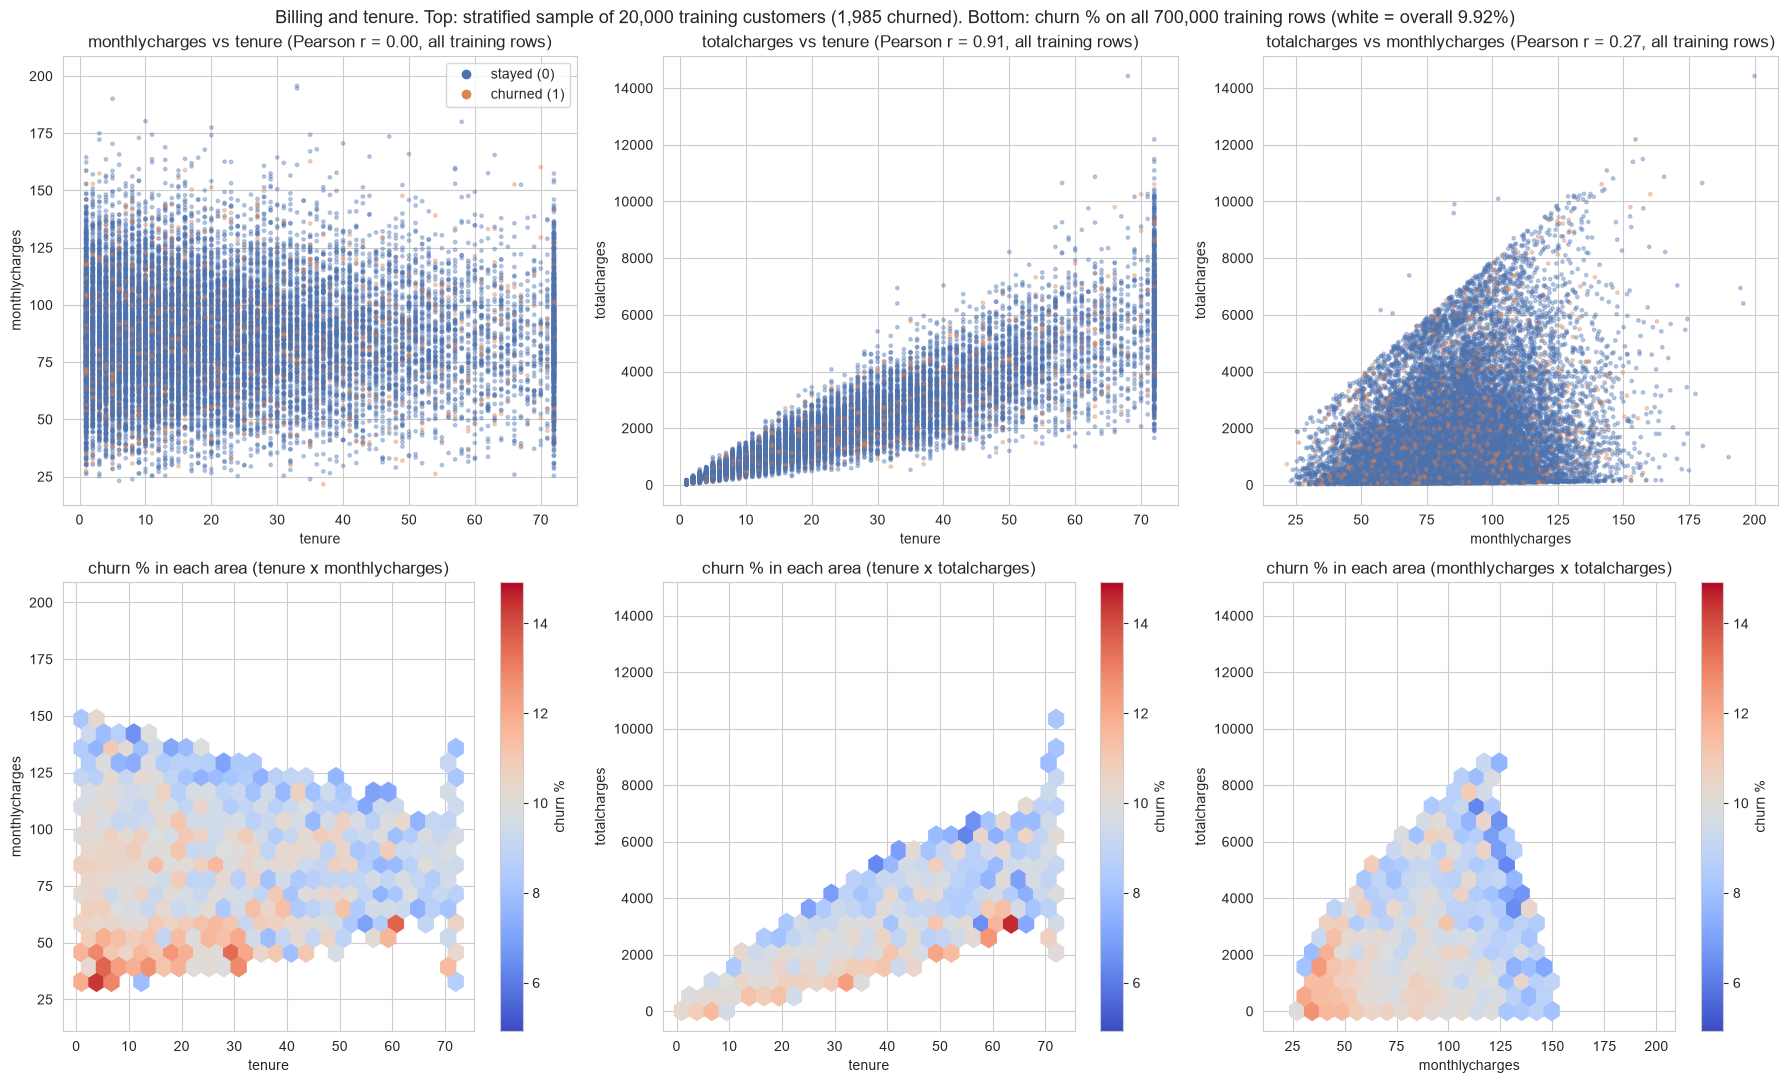

Correlation with churn, all training rows: {'tenure': -0.012, 'monthlycharges': -0.016, 'totalcharges': -0.015}


,customers,churn %
monthlycharges,,
"(0.0, 50.0]",39534,11.34
"(50.0, 70.0]",131042,10.18
"(70.0, 90.0]",236735,9.99
"(90.0, 110.0]",192638,9.93
"(110.0, 130.0]",76458,9.06
"(130.0, 200.0]",23593,8.20


In [14]:
scatter_rows, _ = train_test_split(np.arange(len(train_fe)), train_size=20000, stratify=train_fe[target],
                                   random_state=SEED)
sample = train_fe.iloc[scatter_rows].sample(frac=1, random_state=SEED)    # random drawing order: no group hides the other
scatter_pairs = [("tenure", "monthlycharges"), ("tenure", "totalcharges"), ("monthlycharges", "totalcharges")]
point_colors = sample[target].map(group_colors)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for i, (x, y) in enumerate(scatter_pairs):
    r = train_fe[[x, y]].corr().iloc[0, 1]
    ax = axes[0, i]
    ax.scatter(sample[x], sample[y], s=6, alpha=0.35, c=point_colors)
    ax.set_title(f"{y} vs {x} (Pearson r = {abs(r) if abs(r) < 0.005 else r:.2f}, all training rows)")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    # second row: churn rate in each hexagon, all 700,000 training rows (hexagons with fewer than 300 customers hidden)
    ax = axes[1, i]
    cells = ax.hexbin(train_fe[x], train_fe[y], C=train_fe[target] * 100, reduce_C_function=np.mean, gridsize=25,
                      mincnt=300, cmap="coolwarm", vmin=overall_rate - 5, vmax=overall_rate + 5)
    ax.set_title(f"churn % in each area ({x} x {y})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    fig.colorbar(cells, ax=ax, label="churn %")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color=group_colors[v], label=label)
                           for v, label in [(0, "stayed (0)"), (1, "churned (1)")]])
fig.suptitle(f"Billing and tenure. Top: stratified sample of {len(sample):,} training customers "
             f"({int(sample[target].sum()):,} churned). Bottom: churn % on all {len(train_fe):,} training rows "
             f"(white = overall {overall_rate:.2f}%)", fontsize=13)
plt.tight_layout()
plt.savefig(output_file("figures", "scatter_charges_tenure.png"), bbox_inches="tight")
plt.show()
print("Correlation with churn, all training rows:",
      train_fe[["tenure", "monthlycharges", "totalcharges", target]].corr()[target].drop(target).round(3).to_dict())
bands = pd.cut(train_fe["monthlycharges"], [0, 50, 70, 90, 110, 130, train_fe["monthlycharges"].max()])
charge_bands = train_fe.groupby(bands, observed=True)[target].agg(["size", "mean"])
charge_bands.columns = ["customers", "churn %"]
charge_bands["churn %"] = (charge_bands["churn %"] * 100).round(2)
charge_bands

<div dir="rtl">

**Scatter plots للفاتورة والـ tenure:** الصف الأول sample فيه 20,000 عميل (stratified، `SEED`)، ولون كل نقطة حسب
الـ churn. عشان الـ 700,000 نقطة كانت هتغطي بعض (overplotting)، استخدمنا sample و `alpha`، ورسمنا النقط بترتيب عشوائي
عشان ولا لون يغطي التاني.

- **`monthlycharges` مع `tenure`:** r = 0.00، يعني مالهمش علاقة.
- **`totalcharges` مع `tenure`:** r = 0.91، منطقي: الإجمالي ≈ الفاتورة × عدد الشهور (شكل المروحة).
- **`totalcharges` مع `monthlycharges`:** r = 0.27.
- **اللي مشيوا متوزعين في كل حتة** في الـ scatter، مفيش منطقة واضحة.

**الصف التاني** بيحسب **نسبة الـ churn في كل منطقة** على الـ 700,000 صف كلهم (hexbin، والمناطق اللي فيها أقل من 300
عميل مش ظاهرة عشان نسبتها مش ثابتة). الأبيض = النسبة العامة، الأحمر = أعلى، الأزرق = أقل. هنا بيبان نمط مش باين في
الـ scatter: **الفاتورة الشهرية القليلة معاها churn أعلى شوية**. الجدول تحت بيأكده: 11.34% لما الفاتورة 50 أو أقل،
مقابل 8.20% فوق 130. الـ correlation الخطي صغير جدًا (r = −0.017) لأن الفرق موجود في الأطراف بس وأغلب العملاء في النص.

**الخلاصة:** الفاتورة والـ tenure لوحدهم مابيفصلوش اللي هيمشي، بس علاقة الفاتورة الشهرية بالـ churn **مش خطية**،
وده يستاهل المرحلة 3 تبص عليه بموديلات زي الـ trees. وده **ارتباط (association) مش سببية**: مانقدرش نقول إن رفع
الفاتورة بيقلل الـ churn.

</div>

### 3b. Statistical tests

In [15]:
categorical_tests = category_cols + ["tenure_group"] + binary_cols + ["addons_without_internet"]

rows = []
for col in categorical_tests:
    table = pd.crosstab(train_fe[col], train_fe[target])
    chi2_value, p_value, dof, expected = chi2_contingency(table, correction=False)
    cramers_v = np.sqrt(chi2_value / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"feature": col, "test": "chi-square", "statistic": chi2_value, "p_value": p_value,
                 "effect_size_name": "Cramér's V", "effect_size": cramers_v, "effect_r": cramers_v})

chi_results = pd.DataFrame(rows)
chi_results.sort_values("effect_size", ascending=False).round(4)

,feature,test,statistic,p_value,effect_size_name,effect_size,effect_r
3,contract,chi-square,13585.1989,0.0000,Cramér's V,0.1393,0.1393
13,has_tech_support,chi-square,1410.5056,0.0000,Cramér's V,0.0449,0.0449
10,has_online_security,chi-square,714.3753,0.0000,Cramér's V,0.0319,0.0319
9,has_internet_service,chi-square,177.4349,0.0000,Cramér's V,0.0159,0.0159
16,addons_without_internet,chi-square,124.1070,0.0000,Cramér's V,0.0133,0.0133
5,tenure_group,chi-square,94.6408,0.0000,Cramér's V,0.0116,0.0116
12,has_device_protection,chi-square,15.6639,0.0001,Cramér's V,0.0047,0.0047
11,has_online_backup,chi-square,15.3472,0.0001,Cramér's V,0.0047,0.0047
2,marital_status,chi-square,4.9232,0.1775,Cramér's V,0.0027,0.0027
8,has_phone_service,chi-square,4.4964,0.0340,Cramér's V,0.0025,0.0025


<div dir="rtl">

### ليه statistical tests؟

عاوزين نعرف كل عمود **مرتبط بالـ churn ولا لأ، وقد إيه**. الاختبارات كلها **على الـ train بس**، عشان
الـ validation والـ test يفضلوا ماحدش شافهم.

**الاختبار الأول، Chi-Square (درس Statistics):** للأعمدة النصية والـ 0/1.

- `pd.crosstab` بيعمل جدول: كل فئة × (فضل / مشي).
- `chi2_contingency` بيرجّع قيمة الـ Chi-Square والـ p-value.
- **`correction=False`:** في الجداول 2×2 الـ scipy بيعمل تصحيح اسمه Yates لوحده. الـ Cramér's V متعرّف على الـ
  Chi-Square من غير تصحيح، والتصحيح ده معمول للعينات الصغيرة، وإحنا عندنا 700 ألف. كده كل الجداول بتتحسب بنفس
  الطريقة.
- **Cramér's V** = الجذر التربيعي لـ (Chi-Square ÷ (عدد العملاء × (أصغر بُعد في الجدول − 1))). ده مقياس قوة
  العلاقة من 0 لـ 1. وبما إن الـ churn فيه فئتين بس، أصغر بُعد دايمًا 2، والـ V هنا هو نفسه الـ correlation بين
  العمود والـ churn.

**النتيجة:** `contract` أقوى عمود نصّي (V = 0.139). بعده `has_tech_support` (0.045). الباقي قريب من الصفر.

</div>

In [16]:
numeric_tests = numeric_cols + new_numeric + log_cols

rows = []
for col in numeric_tests:
    data = train_fe[[col, target]].dropna()
    f_value, p_value = f_classif(data[[col]], data[target])
    churned = data[data[target] == 1][col]
    stayed = data[data[target] == 0][col]
    pooled_std = np.sqrt(((len(churned) - 1) * churned.var() + (len(stayed) - 1) * stayed.var())
                         / (len(churned) + len(stayed) - 2))
    cohens_d = (churned.mean() - stayed.mean()) / pooled_std
    r_value, r_p_value = pearsonr(data[col], data[target])      # point-biserial correlation with churn
    rows.append({"feature": col, "test": "ANOVA F-test", "statistic": f_value[0], "p_value": p_value[0],
                 "effect_size_name": "Cohen's d", "effect_size": cohens_d, "effect_r": abs(r_value)})

anova_results = pd.DataFrame(rows)
anova_results.sort_values("effect_r", ascending=False).round(4)

,feature,test,statistic,p_value,effect_size_name,effect_size,effect_r
7,customer_satisfaction,ANOVA F-test,5043.8474,0.0000,Cohen's d,-0.2867,0.0854
8,num_complaints,ANOVA F-test,4310.4192,0.0000,Cohen's d,0.2665,0.0794
9,num_service_calls,ANOVA F-test,4210.1059,0.0000,Cohen's d,0.2594,0.0773
19,m2m_x_complaints,ANOVA F-test,3062.0843,0.0000,Cohen's d,0.2246,0.0670
10,late_payments,ANOVA F-test,1532.2799,0.0000,Cohen's d,0.1565,0.0467
15,complaints_per_month,ANOVA F-test,959.4270,0.0000,Cohen's d,0.1257,0.0376
16,calls_per_month,ANOVA F-test,873.4385,0.0000,Cohen's d,0.1182,0.0353
6,num_services,ANOVA F-test,740.1511,0.0000,Cohen's d,-0.1088,0.0325
14,active_services,ANOVA F-test,619.8342,0.0000,Cohen's d,-0.0995,0.0297
17,late_payments_per_month,ANOVA F-test,403.9837,0.0000,Cohen's d,0.0804,0.0240


<div dir="rtl">

**الاختبار التاني، ANOVA F-test (Additional Topics: `f_classif`):** للأعمدة الرقمية. بيقارن متوسط العمود بين اللي
مشيوا واللي فضلوا. ولما يبقى فيه مجموعتين بس، ANOVA بيدّي نفس نتيجة الـ t-test بالظبط.

**Cohen's d** = (متوسط اللي مشيوا − متوسط اللي فضلوا) ÷ الانحراف المعياري المشترك. يعني الفرق بين المجموعتين
قد كام انحراف معياري. الإشارة السالبة معناها إن اللي مشيوا قيمتهم أقل، زي الرضا.

**`effect_r`:** عشان نرتب كل الأعمدة (الرقمية والنصية) في ترتيب واحد، محتاجين مقياس واحد. المقياس ده هو الـ
correlation بين العمود والـ churn:

- للأعمدة الرقمية: `pearsonr` بين العمود والـ churn (0/1). ده اسمه **point-biserial correlation**.
- للأعمدة النصية والـ 0/1: الـ Cramér's V، وهو نفس المقياس، زي ما قلنا فوق.

**ليه مش المعادلة المشهورة `|d| / √(d² + 4)`؟** المعادلة دي بتحوّل الـ d لـ r **لو المجموعتين نفس العدد**. هنا
اللي مشيوا 10% بس، فالمعادلة دي بتكبّر الأعمدة الرقمية حوالي 1.7 مرة، وكانت هتحطها فوق `contract` في الترتيب
من غير وجه حق. الـ `pearsonr` بيحسب الـ r الحقيقي من الداتا على طول. والـ p-value بتاعه هو هو بتاع الـ ANOVA.

**النتيجة:** أقوى أعمدة رقمية هي الرضا (d = −0.29)، والشكاوى (0.27)، والمكالمات (0.26)، والـ feature الجديدة
`m2m_x_complaints` (0.22).

</div>

In [17]:
def strength(row):
    value = abs(row["effect_size"])
    if row["effect_size_name"] == "Cohen's d":
        limits = [0.2, 0.5, 0.8]      # Cohen's thresholds for d
    else:
        limits = [0.1, 0.3, 0.5]      # Cohen's thresholds for Cramér's V when the target has 2 classes
    if value < limits[0]:
        return "negligible"
    elif value < limits[1]:
        return "small"
    elif value < limits[2]:
        return "medium"
    return "large"


def interpretation(row):
    if not row["significant (Bonferroni)"]:
        return "not significant"
    if row["test"] == "chi-square":
        text = "churn rate differs between categories"
    elif row["effect_size"] > 0:
        text = "churners have higher values"
    else:
        text = "churners have lower values"
    return text + "; " + row["strength"] + " effect"


stat_tests = pd.concat([chi_results, anova_results]).sort_values("effect_r", ascending=False)
alpha_bonferroni = 0.05 / len(stat_tests)
stat_tests["significant (p < 0.05)"] = stat_tests["p_value"] < 0.05
stat_tests["significant (Bonferroni)"] = stat_tests["p_value"] < alpha_bonferroni
stat_tests["strength"] = stat_tests.apply(strength, axis=1)
stat_tests["interpretation"] = stat_tests.apply(interpretation, axis=1)
stat_tests["rank"] = range(1, len(stat_tests) + 1)
stat_tests.to_csv(output_file("results", "statistical_tests.csv"), index=False)
print("Bonferroni level:", round(alpha_bonferroni, 5))
stat_tests.round(4)

Bonferroni level: 0.00122


,feature,test,statistic,p_value,effect_size_name,effect_size,effect_r,significant (p < 0.05),significant (Bonferroni),strength,interpretation,rank
3,contract,chi-square,13585.1989,0.0000,Cramér's V,0.1393,0.1393,True,True,small,churn rate differs between categories; small e...,1
7,customer_satisfaction,ANOVA F-test,5043.8474,0.0000,Cohen's d,-0.2867,0.0854,True,True,small,churners have lower values; small effect,2
8,num_complaints,ANOVA F-test,4310.4192,0.0000,Cohen's d,0.2665,0.0794,True,True,small,churners have higher values; small effect,3
9,num_service_calls,ANOVA F-test,4210.1059,0.0000,Cohen's d,0.2594,0.0773,True,True,small,churners have higher values; small effect,4
19,m2m_x_complaints,ANOVA F-test,3062.0843,0.0000,Cohen's d,0.2246,0.0670,True,True,small,churners have higher values; small effect,5
10,late_payments,ANOVA F-test,1532.2799,0.0000,Cohen's d,0.1565,0.0467,True,True,negligible,churners have higher values; negligible effect,6
13,has_tech_support,chi-square,1410.5056,0.0000,Cramér's V,0.0449,0.0449,True,True,negligible,churn rate differs between categories; negligi...,7
15,complaints_per_month,ANOVA F-test,959.4270,0.0000,Cohen's d,0.1257,0.0376,True,True,negligible,churners have higher values; negligible effect,8
16,calls_per_month,ANOVA F-test,873.4385,0.0000,Cohen's d,0.1182,0.0353,True,True,negligible,churners have higher values; negligible effect,9
6,num_services,ANOVA F-test,740.1511,0.0000,Cohen's d,-0.1088,0.0325,True,True,negligible,churners have lower values; negligible effect,10


<div dir="rtl">

**جدول الـ Data Analysis Report (FR-09):** لكل عمود فيه اسم الاختبار، والـ statistic، والـ p-value، والـ
effect size، وقوة العلاقة، وتفسير قصير، والترتيب. اتحفظ في `statistical_tests.csv`.

**تصنيف قوة العلاقة:** كل مقياس بالحدود المتعارف عليها بتاعته (Cohen):

| المقياس | negligible | small | medium | large |
|---|---|---|---|---|
| Cohen's d (القيمة المطلقة) | أقل من 0.2 | 0.2 لـ 0.5 | 0.5 لـ 0.8 | 0.8 وفوق |
| Cramér's V (الـ churn فئتين) | أقل من 0.1 | 0.1 لـ 0.3 | 0.3 لـ 0.5 | 0.5 وفوق |

**Bonferroni:** إحنا عاملين 41 اختبار مع بعض. لو استخدمنا 0.05 لكل واحد، ولو مفيش أي علاقة حقيقية، متوقع
حوالي اختبارين (41 × 0.05) يطلعوا significant بالصدفة. التصحيح البسيط ده بيقسم الـ 0.05 على عدد الاختبارات (0.05 ÷ 41 ≈ 0.0012)، والعمود
`significant (Bonferroni)` هو اللي بنعتمد عليه. سبنا عمود الـ 0.05 كمان للمقارنة.

**الـ interpretation:** للأعمدة الرقمية بيقول اللي مشيوا قيمتهم أعلى ولا أقل (من إشارة الـ d)، وللنصية بيقول إن
نسبة الـ churn بتختلف بين الفئات، ومعاه قوة العلاقة.

</div>

In [18]:
print(stat_tests["strength"].value_counts())
print()
print("Significant at p < 0.05:", stat_tests["significant (p < 0.05)"].sum())
print("Significant after Bonferroni:", stat_tests["significant (Bonferroni)"].sum())
print("Significant (Bonferroni) but negligible:",
      ((stat_tests["significant (Bonferroni)"]) & (stat_tests["strength"] == "negligible")).sum())

strength
negligible    36
small          5
Name: count, dtype: int64

Significant at p < 0.05: 25
Significant after Bonferroni: 24
Significant (Bonferroni) but negligible: 19


<div dir="rtl">

**أهم نقطة في المرحلة دي:** من الـ 41 عمود، **25 عمود الـ p-value بتاعهم أقل من 0.05**، و **24 بعد تصحيح
Bonferroni** (اللي خرج هو `has_phone_service`، الـ p بتاعه 0.034). بس **19 من الـ 24 قوة العلاقة بتاعتهم
negligible**.

ليه؟ لأن مع 700 ألف صف، أي فرق صغير جدًا بيطلع significant. عشان كده **الـ effect size هو اللي بيقول العلاقة
مهمة فعلًا ولا لأ**، مش الـ p-value. وده بالظبط السبب إن FR-09 طالب الـ effect size.

**5 أعمدة بس علاقتهم small:** الرضا، ونوع العقد، والشكاوى، والمكالمات، و `m2m_x_complaints`. ومفيش ولا عمود
وصل لـ medium.

</div>

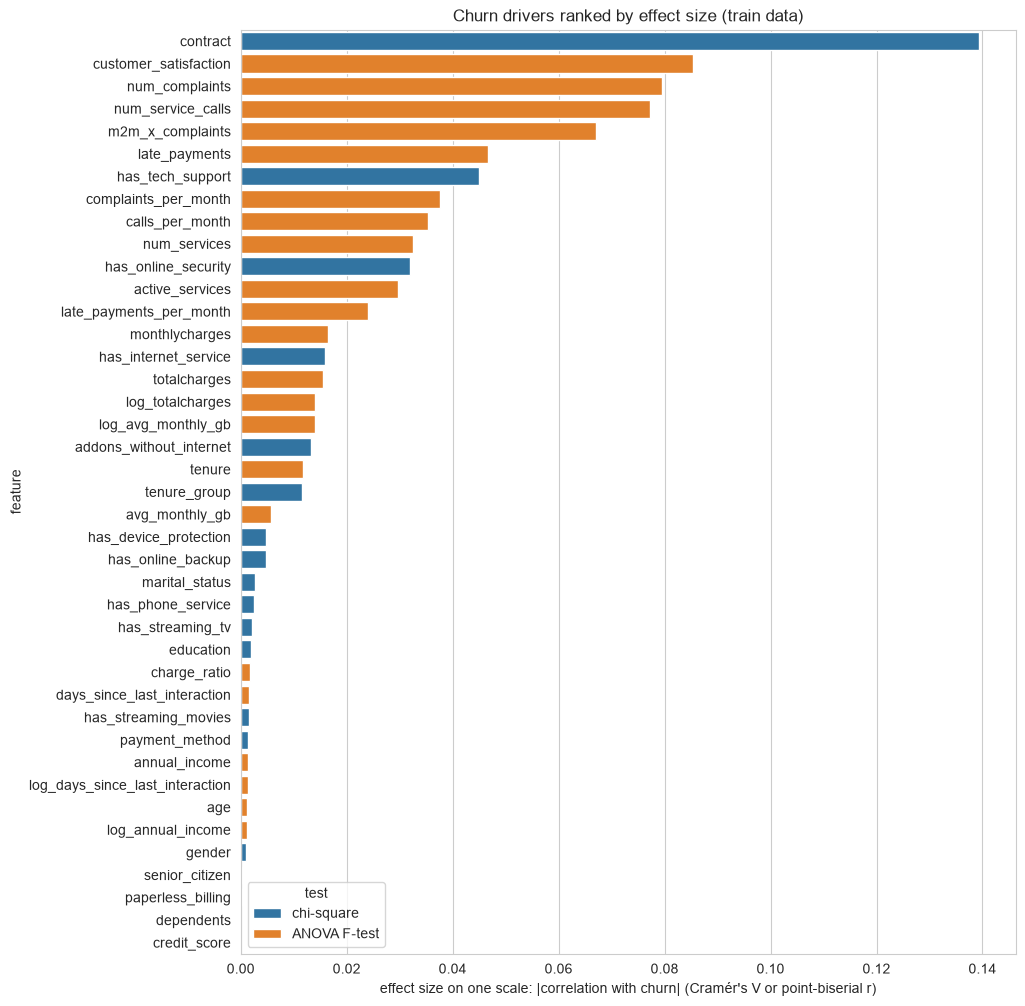

In [19]:
plt.figure(figsize=(10, 12))
sns.barplot(data=stat_tests, x="effect_r", y="feature", hue="test")
plt.title("Churn drivers ranked by effect size (train data)")
plt.xlabel("effect size on one scale: |correlation with churn| (Cramér's V or point-biserial r)")
plt.savefig(output_file("figures", "effect_size_ranking.png"), bbox_inches="tight")
plt.show()

<div dir="rtl">

**كل الـ drivers مرسومين هنا مترتبين بالـ effect size** (`sns.barplot`، درس Seaborn). FR-10 طالب إن كل driver
يظهر في رسمة واحدة على الأقل، والرسمة دي بتغطيهم كلهم.

**ملحوظة:** الرسمة دي للترتيب بس. الأعمدة الرقمية اللي الـ d بتاعها small (زي الرضا، r ≈ 0.085) بتظهر بقيمة
أقل من 0.1، لأن الـ correlation بيقل لما مجموعة من الاتنين تبقى صغيرة (اللي مشيوا 10% بس)، والـ d مابيتأثرش
بده. عشان كده قوة العلاقة (small أو negligible) بنحكم عليها بمقياس كل عمود (d أو V) زي الجدول اللي فوق.

</div>

## 4. Correlation and association (train data only)

Columns in the matrix: 32 | 21 from Phase 1 data, 11 Phase 2 features


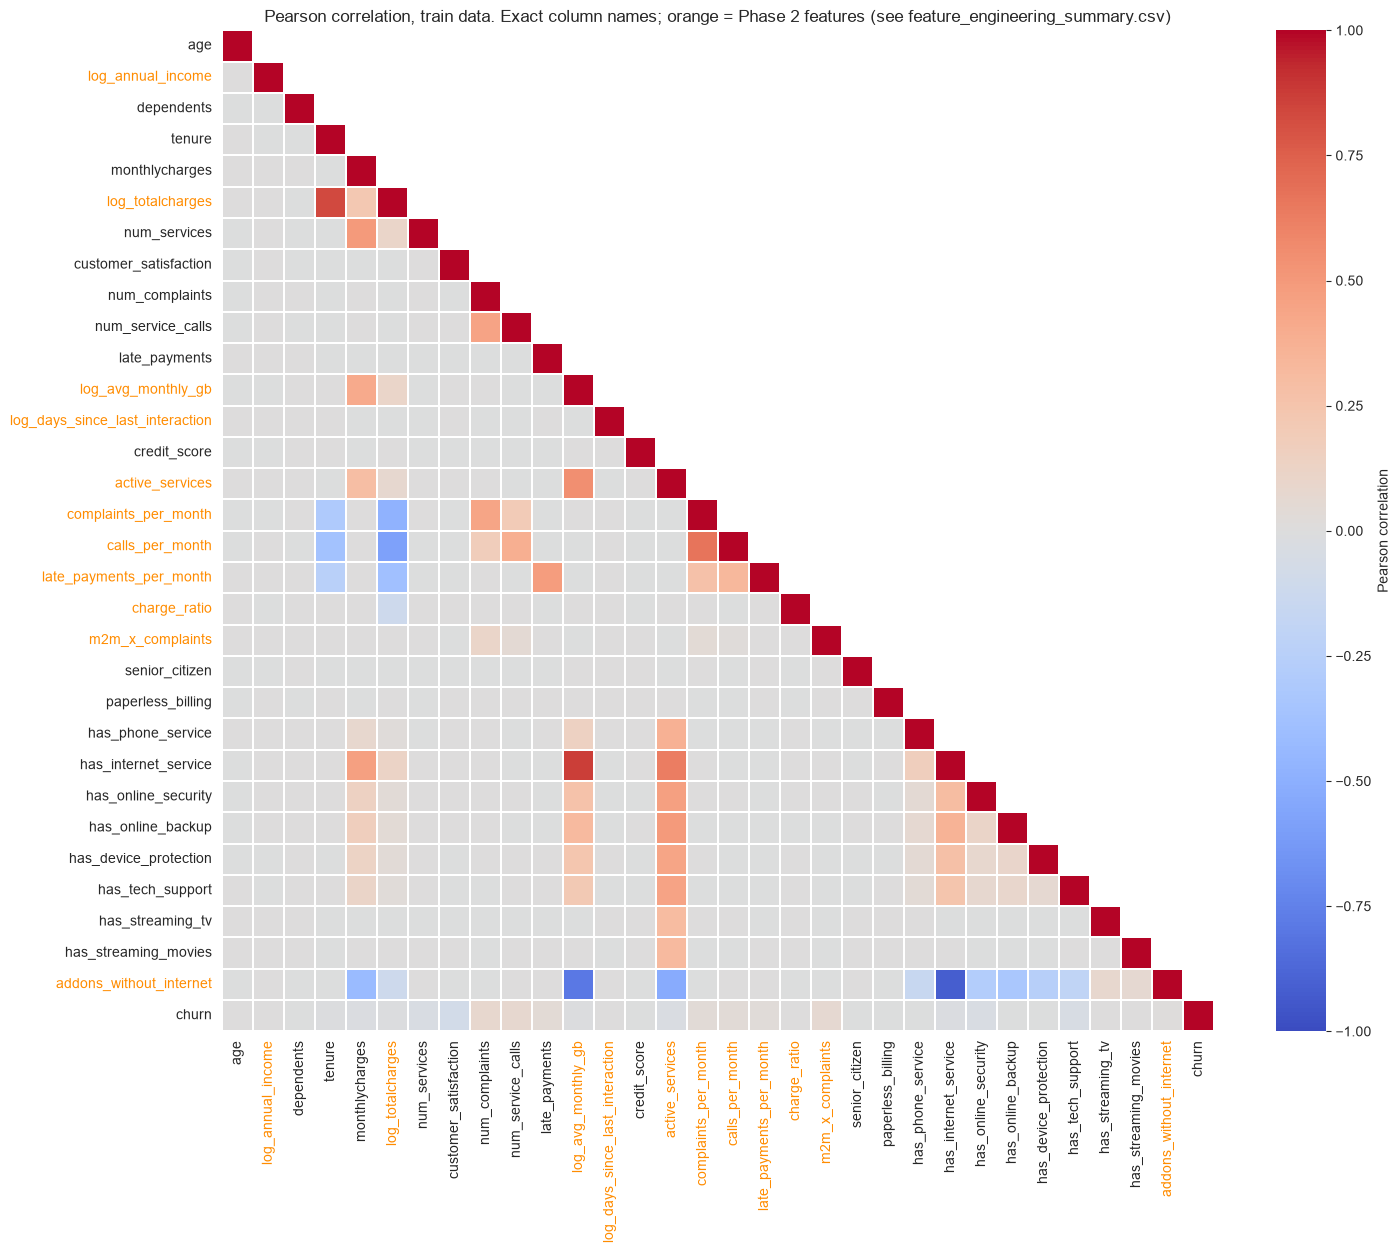

In [20]:
numeric_v2 = ["age", "log_annual_income", "dependents", "tenure", "monthlycharges", "log_totalcharges",
              "num_services", "customer_satisfaction", "num_complaints", "num_service_calls", "late_payments",
              "log_avg_monthly_gb", "log_days_since_last_interaction", "credit_score"] + new_numeric
binary_v2 = binary_cols + ["addons_without_internet"]
category_v2 = category_cols + ["tenure_group"]

# Every column in the matrix must be a real column: a Phase 1 column or one of the 12 documented Phase 2 features
corr_columns = numeric_v2 + binary_v2 + [target]
unknown = [c for c in corr_columns if c not in train_fe.columns or c not in phase1_columns + engineered]
assert not unknown and len(set(corr_columns)) == len(corr_columns), unknown
print("Columns in the matrix:", len(corr_columns), "|", sum(c in phase1_columns for c in corr_columns),
      "from Phase 1 data,", sum(c in engineered for c in corr_columns), "Phase 2 features")

corr = train_fe[corr_columns].corr()          # Pearson; for a 0/1 column this is the point-biserial (or phi) correlation

sns.set_style("white")                                    # no grid lines behind the hidden half
plt.figure(figsize=(16, 13))
hidden = np.triu(np.ones(corr.shape, dtype=bool), k=1)      # the upper half repeats the lower half
ax = sns.heatmap(corr, mask=hidden, vmax=1, vmin=-1, center=0, cmap="coolwarm", linewidths=0.2,
                 cbar_kws={"label": "Pearson correlation"})
for label in ax.get_xticklabels() + ax.get_yticklabels():
    if label.get_text() in engineered:
        label.set_color("darkorange")
plt.title("Pearson correlation, train data. Exact column names; orange = Phase 2 features "
          "(see feature_engineering_summary.csv)")
plt.savefig(output_file("figures", "correlation_v2.png"), bbox_inches="tight")
plt.show()

<div dir="rtl">

### الـ correlation matrix بعد مراجعة الأسماء

**المراجعة:** زميل سأل عن أسماء زي `m2m_x_complaints` في الرسمة، هل موجودة فعلًا؟ الخلية دي بتتأكد بالكود (`assert`)
إن **كل عمود في الـ matrix عمود حقيقي**: يا إما من داتا المرحلة 1، يا إما واحد من الـ 12 feature الموثّقين في
`feature_engineering_summary.csv`. النتيجة: 32 عمود = 21 من المرحلة 1 + 11 feature من المرحلة 2، ومفيش تكرار.

- **`m2m_x_complaints` feature حقيقية من المرحلة 2:** معمولة في `add_features` (عدد الشكاوى لو العقد شهري، وصفر
  غير كده)، وموثّقة، ومراجعة الـ leakage بتاعتها اتعملت، ومتطبقة على الـ train والـ validation والـ test بنفس الطريقة.
  هي مش موجودة في الداتا الخام لأنها **معمولة منها**.
- عشان مايبقاش فيه لبس تاني: **الـ features الجديدة مكتوبة بلون برتقالي**، والأسماء هي أسماء الأعمدة بالظبط.
- القوائم: `numeric_v2` (الأرقام، والـ 4 الـ skewed بنسخة الـ log، والـ 6 الجداد)، و `binary_v2` (الـ 0/1 و
  `addons_without_internet`)، و `category_v2` (النصوص و `tenure_group`).
- النص اللي فوق القطر متشال لأنه تكرار للي تحته.
- **Pearson** بين عمودين 0/1 هو الـ phi، وبين رقم و 0/1 هو الـ point-biserial، فهو مناسب لكل الأعمدة اللي هنا.
  الأعمدة النصية مش هنا (Pearson مالوش معنى ليها)، ولها رسمة Cramér's V تحت.

</div>

In [21]:
spearman = train_fe[corr_columns].corr(method="spearman")     # rank correlation: monotonic, robust to skew and outliers
pairs = []
for i, col1 in enumerate(numeric_v2 + binary_v2):
    for col2 in (numeric_v2 + binary_v2)[i + 1:]:
        if abs(corr.loc[col1, col2]) > 0.7 or abs(spearman.loc[col1, col2]) > 0.7:
            pairs.append({"feature_1": col1, "feature_2": col2, "pearson": round(corr.loc[col1, col2], 3),
                          "spearman": round(spearman.loc[col1, col2], 3),
                          "above 0.7 with": "both" if min(abs(corr.loc[col1, col2]), abs(spearman.loc[col1, col2])) > 0.7
                          else ("Spearman only" if abs(spearman.loc[col1, col2]) > 0.7 else "Pearson only")})
correlation_pairs = pd.DataFrame(pairs).sort_values("spearman", key=abs, ascending=False)
correlation_pairs.to_csv(output_file("results", "correlation_pairs.csv"), index=False)
print("Largest |correlation with churn|: Pearson", round(corr[target].drop(target).abs().max(), 3),
      "| Spearman", round(spearman[target].drop(target).abs().max(), 3))
correlation_pairs

Largest |correlation with churn|: Pearson 0.085 | Spearman 0.08


,feature_1,feature_2,pearson,spearman,above 0.7 with
3,late_payments,late_payments_per_month,0.477,0.971,Spearman only
0,tenure,log_totalcharges,0.832,0.959,both
6,has_internet_service,addons_without_internet,-0.915,-0.915,both
1,num_complaints,complaints_per_month,0.443,0.914,Spearman only
2,num_service_calls,calls_per_month,0.384,0.719,Spearman only
4,log_avg_monthly_gb,has_internet_service,0.870,0.619,Pearson only
5,log_avg_monthly_gb,addons_without_internet,-0.796,-0.566,Pearson only


<div dir="rtl">

**الأزواج المرتبطة جدًا (|r| > 0.7) بطريقتين:** Pearson بيقيس العلاقة **الخطية**، و **Spearman** بيقيس العلاقة
**الترتيبية** (monotonic)، ومش بيتأثر بالـ skew والقيم الكبيرة. حسبنا الاتنين وحفظنا الأزواج في
`results/correlation_pairs.csv`.

- **الـ 4 أزواج القدام** (Pearson) لسه موجودين: الإنترنت مع `addons_without_internet` (−0.915)، والاستهلاك مع الإنترنت
  (0.870)، والـ tenure مع `log_totalcharges` (0.832)، والاستهلاك مع `addons_without_internet` (−0.796).
- **Spearman طلّع 3 أزواج جداد** كان Pearson مش شايفهم: كل معدل شهري مع العدد الأصلي بتاعه:
  `late_payments` مع `late_payments_per_month` (0.971)، و `num_complaints` مع `complaints_per_month` (0.914)، و
  `num_service_calls` مع `calls_per_month` (0.719). Pearson كان بيدّيهم 0.38–0.48 بس، لأن القسمة على tenure صغير
  بتعمل قيم كبيرة جدًا (skew) بتضعّف الـ correlation الخطي.

**المعنى:** المعدلات الشهرية مكررة تقريبًا مع الأعداد الأصلية في الترتيب، وده بيفسّر جزء من ليه ماضافتش للـ Logistic
Regression. القرار زي ما هو: **مش بنشيل حاجة بإيدينا**، والـ RFE في الخطوة 6 هو اللي اختار (ومااختارش ولا معدل شهري).

</div>

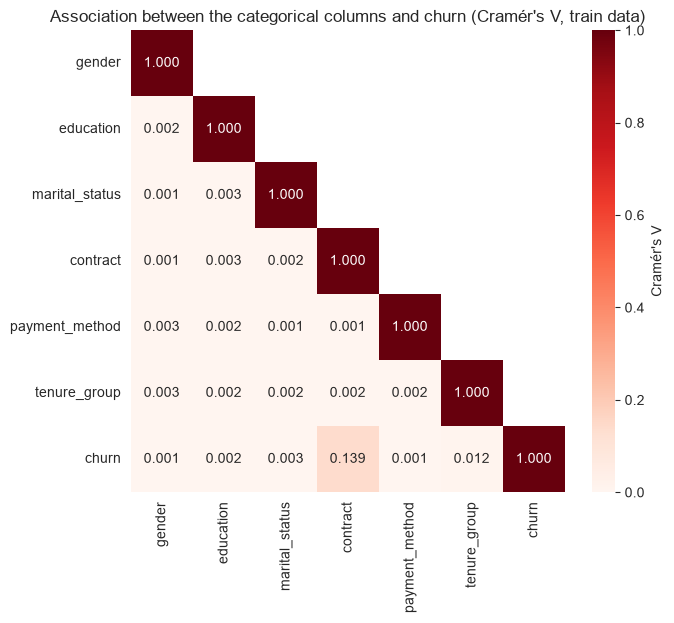

,gender,education,marital_status,contract,payment_method,tenure_group,churn
gender,1.000,0.002,0.001,0.001,0.003,0.003,0.001
education,0.002,1.000,0.003,0.003,0.002,0.002,0.002
marital_status,0.001,0.003,1.000,0.002,0.001,0.002,0.003
contract,0.001,0.003,0.002,1.000,0.001,0.002,0.139
payment_method,0.003,0.002,0.001,0.001,1.000,0.002,0.001
tenure_group,0.003,0.002,0.002,0.002,0.002,1.000,0.012
churn,0.001,0.002,0.003,0.139,0.001,0.012,1.000


In [22]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2_value = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2_value / (table.values.sum() * (min(table.shape) - 1)))


assoc_columns = category_v2 + [target]
association = pd.DataFrame(1.0, index=assoc_columns, columns=assoc_columns)
for i, col1 in enumerate(assoc_columns):
    for col2 in assoc_columns[i + 1:]:
        association.loc[col1, col2] = association.loc[col2, col1] = cramers_v(train_fe[col1], train_fe[col2])

plt.figure(figsize=(7, 6))
sns.heatmap(association, mask=np.triu(np.ones(association.shape, dtype=bool), k=1), vmin=0, vmax=1, cmap="Reds",
            annot=True, fmt=".3f", cbar_kws={"label": "Cramér's V"})
plt.title("Association between the categorical columns and churn (Cramér's V, train data)")
plt.savefig(output_file("figures", "categorical_association_v2.png"), bbox_inches="tight")
plt.show()
sns.set_style("whitegrid")
association.round(3)

<div dir="rtl">

**الأعمدة النصية: Cramér's V.** الـ Pearson مالوش معنى مع النصوص، فالمقياس الصح للعلاقة بين عمودين فئويين هو
**Cramér's V** (من 0 لـ 1، نفس المعادلة اللي في 3b). الـ matrix دي فيها الـ 6 أعمدة النصية والـ churn.

- **الأعمدة النصية مش مرتبطة ببعض** (كل القيم 0.003 أو أقل)، فمفيش تكرار بينهم.
- **مع الـ churn:** العقد 0.139 (الوحيد اللي ليه علاقة، small)، و `tenure_group` 0.012، والباقي حوالي صفر.

**ارتباط مش سببية:** كل الأرقام في القسم ده بتقول "بيتحركوا مع بعض"، مش "واحد بيسبب التاني".

</div>

## 5. Updated preprocessing pipeline

In [23]:
num_pipeline = Pipeline(steps=[
    ("selector", DataFrameSelector(numeric_v2)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categ_pipeline = Pipeline(steps=[
    ("selector", DataFrameSelector(category_v2)),
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="first", sparse_output=False))
])

ready_pipeline = Pipeline(steps=[
    ("selector", DataFrameSelector(binary_v2)),
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

all_pipeline = FeatureUnion(transformer_list=[
    ("numerical", num_pipeline),
    ("categorical", categ_pipeline),
    ("ready", ready_pipeline)
])

<div dir="rtl">

**نفس تصميم الـ pipeline بتاع المرحلة الأولى و Session 8 بالظبط**، الفرق الوحيد إن القوائم بقت `_v2`.
`tenure_group` هتتحول بالـ One-Hot، والـ features الرقمية الجديدة هتتملا بالـ median وتتعمل scaling.

</div>

In [24]:
X_train = train_fe.drop(columns=["customer_id", target])
y_train = train_fe[target]
X_val = val_fe.drop(columns=["customer_id", target])
y_val = val_fe[target]
X_test = test_fe.drop(columns=["customer_id", target])

X_train_final = all_pipeline.fit_transform(X_train)
X_val_final = all_pipeline.transform(X_val)
X_test_final = all_pipeline.transform(X_test)

out_categ_cols = all_pipeline.named_transformers["categorical"].named_steps["ohe"].get_feature_names_out(category_v2)
final_cols = numeric_v2 + list(out_categ_cols) + binary_v2

X_train_final = pd.DataFrame(X_train_final, columns=final_cols)
X_val_final = pd.DataFrame(X_val_final, columns=final_cols)
X_test_final = pd.DataFrame(X_test_final, columns=final_cols)

print("Features after the pipeline:", X_train_final.shape[1])
print("Rows:", X_train_final.shape[0], X_val_final.shape[0], X_test_final.shape[0])
print("Missing values:", X_train_final.isnull().sum().sum(), X_val_final.isnull().sum().sum(), X_test_final.isnull().sum().sum())

Features after the pipeline: 49
Rows: 700000 150000 150000
Missing values: 0 0 0


<div dir="rtl">

- **`fit_transform` على الـ train بس**، و `transform` على الـ validation والـ test (FR-12).
- **النتيجة:** 49 feature، ونفس عدد الصفوف (700,000 و 150,000 و 150,000)، ومفيش ولا قيمة ناقصة.
- الـ test اتعمله `transform` بس عشان يتحفظ جاهز للمرحلة 3. مااتعملش عليه أي حاجة تانية.

</div>

## 6. Feature selection with RFE

In [25]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_final), columns=final_cols)
X_val_scaled = pd.DataFrame(scaler.transform(X_val_final), columns=final_cols)

<div dir="rtl">

**ليه `StandardScaler` تاني قبل الـ RFE؟** الـ RFE بيرتّب الـ features حسب حجم الـ coefficient في الـ Logistic
Regression. الـ pipeline بيعمل scaling للأرقام بس، والأعمدة الـ 0/1 بتفضل زي ما هي. فلو ماعملناش scaling للكل،
الـ coefficients مش هتبقى قابلة للمقارنة، والـ RFE هيختار غلط.

الـ scaler بيتعمله `fit` على الـ train بس، وبعدين `transform` على الـ validation.

</div>

In [26]:
RFE_SAMPLE_SIZE = 100000          # stratified sample of the training data (team breakdown: RFE on a stratified sample)
rfe_rows, _ = train_test_split(np.arange(len(y_train)), train_size=RFE_SAMPLE_SIZE, stratify=y_train,
                               random_state=SEED)
X_rfe = X_train_scaled.iloc[rfe_rows]
y_rfe = y_train.iloc[rfe_rows]
print("RFE sample:", len(y_rfe), "of", len(y_train), "training rows | churn rate:", round(y_rfe.mean(), 4),
      "(whole train:", round(y_train.mean(), 4), ")")

rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=1, step=1)
rfe.fit(X_rfe, y_rfe)

ranking = pd.DataFrame({"feature": final_cols, "rfe_rank": rfe.ranking_}).sort_values("rfe_rank")
ranking

RFE sample: 100000 of 700000 training rows | churn rate: 0.0992 (whole train: 0.0992 )


,feature,rfe_rank
30,contract_two_year,1
29,contract_one_year,2
7,customer_satisfaction,3
9,num_service_calls,4
8,num_complaints,5
45,has_tech_support,6
10,late_payments,7
6,num_services,8
42,has_online_security,9
4,monthlycharges,10


<div dir="rtl">

**الـ RFE (Additional Topics، Wrapper Method)، بنفس طريقة الكورس `RFE(estimator=LogisticRegression(), ...)`:**

- **الـ estimator:** `LogisticRegression(max_iter=1000)`. خلّينا `max_iter` 1000 عشان الموديل يوصل لحل.
- **`step=1`:** بيشيل feature واحدة في كل خطوة، الأضعف.
- **`n_features_to_select=1`:** بيكمّل لحد ما يفضل feature واحدة. كده بناخد **ترتيب كامل** لكل الـ 49 feature،
  ورقم 1 هو الأهم.
- **الداتا: stratified sample من الـ train بس**، 100,000 صف من الـ 700,000، زي ما تقسيم الفريق طالب. اتاخدوا بـ
  `train_test_split` مع `stratify=y_train`، فنسبة الـ churn في الـ sample هي هي بتاعة الـ train (السطر اللي فوق
  بيطبعهم الاتنين). الـ RFE بيدرّب Logistic Regression 48 مرة، فالـ sample بيخلّيه أسرع، وحجمه كبير كفاية إن
  الترتيب يبقى ثابت. والـ validation والـ test مادخلوش خالص (FR-13).

**الترتيب:** العقد أول حاجة، بعده الرضا والمكالمات والشكاوى والـ tech support والتأخير في الدفع. والـ
demographics في الآخر.

</div>

In [27]:
rfecv = RFECV(estimator=LogisticRegression(max_iter=1000), step=1, cv=StratifiedKFold(n_splits=5),
              scoring="roc_auc", min_features_to_select=1)
rfecv.fit(X_rfe, y_rfe)

k_results = pd.DataFrame({"number_of_features": rfecv.cv_results_["n_features"],
                          "cv_auc": rfecv.cv_results_["mean_test_score"].round(4)})
k_results[k_results["number_of_features"].isin([1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 20, 30, 40, 49])]

,number_of_features,cv_auc
0,1,0.6037
2,3,0.6499
4,5,0.6731
6,7,0.6817
7,8,0.6840
8,9,0.6860
9,10,0.6864
10,11,0.6864
11,12,0.6866
14,15,0.6861


<div dir="rtl">

**نحتفظ بكام feature؟** بنقرر بالـ **cross-validation على الـ RFE sample نفسه**، مش بالـ validation، عشان
اختيار الـ features كله يبقى من الـ train بس.

- `RFECV` هو نفس الـ RFE، بس بيعمله جوه 5 folds (`StratifiedKFold`): في كل fold بيعمل الـ RFE على الـ folds
  بتاعة التدريب، ويحسب الـ ROC-AUC على الـ fold اللي فاضل لكل عدد features من 1 لـ 49. والنتيجة متوسط الـ 5.
- الجدول بيعرض جزء من الأعداد، والرسمة تحت فيها كلهم.
- الـ ROC-AUC مش بيعتمد على threshold، فمش محتاجين نختار threshold، وده شغل المرحلة 3.

</div>

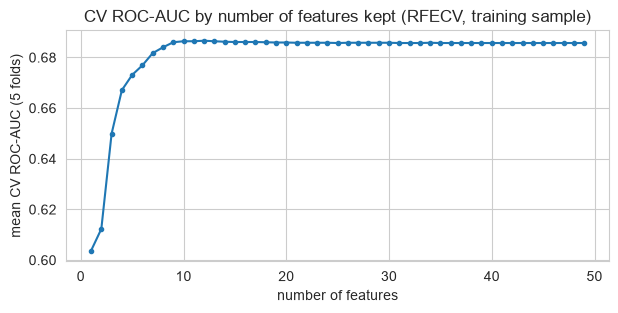

In [28]:
plt.figure(figsize=(7, 3))
plt.plot(k_results["number_of_features"], k_results["cv_auc"], marker="o", markersize=3)
plt.title("CV ROC-AUC by number of features kept (RFECV, training sample)")
plt.xlabel("number of features")
plt.ylabel("mean CV ROC-AUC (5 folds)")
plt.savefig(output_file("figures", "rfe_number_of_features.png"), bbox_inches="tight")
plt.show()

<div dir="rtl">

الرسمة بتبيّن إن الأداء **بيوقف عن الزيادة بعد حوالي 9 features**: من 1 لـ 9 فيه زيادة كبيرة (من 0.60 لـ 0.686)،
وبعد كده الخط مسطّح، وبعد 12 بيقل حبة صغيرة جدًا.

</div>

In [29]:
best_auc = k_results["cv_auc"].max()
n_selected = k_results[k_results["cv_auc"] >= best_auc - 0.001]["number_of_features"].min()
selected_features = ranking["feature"].head(n_selected).tolist()
eliminated_features = ranking["feature"].iloc[n_selected:].tolist()

print("Best CV AUC:", best_auc, "| features kept:", n_selected, "of", len(final_cols))
print("\nSelected:", selected_features)
print("\nEliminated:", eliminated_features)

ranking["selected"] = ranking["feature"].isin(selected_features)
ranking.to_csv(output_file("results", "rfe_ranking.csv"), index=False)

Best CV AUC: 0.6866 | features kept: 9 of 49

Selected: ['contract_two_year', 'contract_one_year', 'customer_satisfaction', 'num_service_calls', 'num_complaints', 'has_tech_support', 'late_payments', 'num_services', 'has_online_security']

Eliminated: ['monthlycharges', 'log_totalcharges', 'complaints_per_month', 'tenure', 'tenure_group_7-12', 'education_phd', 'gender_male', 'payment_method_electronic_check', 'marital_status_married', 'paperless_billing', 'payment_method_mailed_check', 'calls_per_month', 'log_avg_monthly_gb', 'addons_without_internet', 'has_streaming_tv', 'log_days_since_last_interaction', 'tenure_group_49+', 'm2m_x_complaints', 'dependents', 'age', 'education_high_school', 'education_master', 'education_college', 'has_streaming_movies', 'senior_citizen', 'has_phone_service', 'active_services', 'tenure_group_25-48', 'tenure_group_13-24', 'has_device_protection', 'has_online_backup', 'credit_score', 'charge_ratio', 'gender_other', 'has_internet_service', 'log_annual_inc

<div dir="rtl">

**قاعدة الاختيار:** أقل عدد features الـ CV AUC بتاعه أقل من أفضل CV AUC بـ 0.001 أو أقل، عشان ناخد أبسط موديل
من غير ما نخسر أداء. أفضل CV AUC هو 0.6866 (بـ 12 feature)، و 9 features بيدّوا 0.6860، فالنتيجة **9 features**.
القرار ده اتاخد من الـ train بس، والـ validation مادخلش فيه.

- **اللي اتختاروا (9):** `contract_two_year`، `contract_one_year`، `customer_satisfaction`، `num_service_calls`،
  `num_complaints`، `has_tech_support`، `late_payments`، `num_services`، `has_online_security`.
- **اللي اتشالوا (40):** كل الباقي، ومعاهم كل الـ features الجديدة. الترتيب الكامل في `results/rfe_ranking.csv`.

</div>

In [30]:
phase1_pipeline = pickle.load(open(phase1_file("pipeline.pkl"), "rb"))
X_train_p1 = phase1_pipeline.transform(train_df.drop(columns=["customer_id", target]))
X_val_p1 = phase1_pipeline.transform(val_df.drop(columns=["customer_id", target]))

phase1_model = Pipeline(steps=[("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
phase1_model.fit(X_train_p1, y_train)
full_model = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
selected_model = LogisticRegression(max_iter=1000).fit(X_train_scaled[selected_features], y_train)

def cv_scores(model, X, y):
    # 5-fold CV: in every fold a fresh copy of the WHOLE model (preprocessing included) is fitted on the
    # training folds only, then scored on the held-out fold. Returns the mean ROC-AUC and PR-AUC.
    roc_scores, pr_scores = [], []
    for train_index, test_index in StratifiedKFold(n_splits=5).split(X, y):
        fold_model = copy.deepcopy(model)
        fold_model.fit(X.iloc[train_index], y.iloc[train_index])
        probability = fold_model.predict_proba(X.iloc[test_index])[:, 1]
        roc_scores.append(roc_auc_score(y.iloc[test_index], probability))
        pr_scores.append(average_precision_score(y.iloc[test_index], probability))
    return np.mean(roc_scores), np.mean(pr_scores)


cv_phase1 = Pipeline(steps=[("prep", phase1_pipeline), ("scaler", StandardScaler()),
                            ("lr", LogisticRegression(max_iter=1000))])
cv_all = Pipeline(steps=[("prep", all_pipeline), ("scaler", StandardScaler()),
                         ("lr", LogisticRegression(max_iter=1000))])
def cv_scores_selected(X, y):
    # Same 5 folds. In every fold the preprocessing, the scaler and RFE are refitted on the training folds only,
    # with RFE on a stratified sample of them (as above); the model then learns from all training-fold rows.
    roc_scores, pr_scores = [], []
    for train_index, test_index in StratifiedKFold(n_splits=5).split(X, y):
        fold_prep = copy.deepcopy(all_pipeline)
        fold_scaler = StandardScaler()
        X_fit = fold_scaler.fit_transform(fold_prep.fit_transform(X.iloc[train_index]))
        X_held = fold_scaler.transform(fold_prep.transform(X.iloc[test_index]))
        y_fit = y.iloc[train_index]
        sample, _ = train_test_split(np.arange(len(y_fit)), train_size=RFE_SAMPLE_SIZE, stratify=y_fit,
                                     random_state=SEED)
        fold_rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=n_selected, step=1)
        fold_rfe.fit(X_fit[sample], y_fit.iloc[sample])
        fold_model = LogisticRegression(max_iter=1000).fit(X_fit[:, fold_rfe.support_], y_fit)
        probability = fold_model.predict_proba(X_held[:, fold_rfe.support_])[:, 1]
        roc_scores.append(roc_auc_score(y.iloc[test_index], probability))
        pr_scores.append(average_precision_score(y.iloc[test_index], probability))
    return np.mean(roc_scores), np.mean(pr_scores)


cv_results = [cv_scores(cv_phase1, X_train, y_train),
              cv_scores(cv_all, X_train, y_train),
              cv_scores_selected(X_train, y_train)]
val_probabilities = [phase1_model.predict_proba(X_val_p1)[:, 1],
                     full_model.predict_proba(X_val_scaled)[:, 1],
                     selected_model.predict_proba(X_val_scaled[selected_features])[:, 1]]

comparison = pd.DataFrame({
    "feature set": ["Phase 1 features (no new features)", "all Phase 2 features", "RFE selected"],
    "number of features": [X_train_p1.shape[1], len(final_cols), len(selected_features)],
    "CV ROC-AUC (train, 5 folds)": [roc for roc, pr in cv_results],
    "CV PR-AUC (train, 5 folds)": [pr for roc, pr in cv_results],
    "validation ROC-AUC": [roc_auc_score(y_val, p) for p in val_probabilities],
    "validation PR-AUC": [average_precision_score(y_val, p) for p in val_probabilities],
}).round(4)
comparison

,feature set,number of features,"CV ROC-AUC (train, 5 folds)","CV PR-AUC (train, 5 folds)",validation ROC-AUC,validation PR-AUC
0,Phase 1 features (no new features),38,0.6844,0.2017,0.6869,0.2026
1,all Phase 2 features,49,0.6844,0.2016,0.6869,0.2025
2,RFE selected,9,0.6841,0.2007,0.6865,0.2015


<div dir="rtl">

**المقارنة اللي FR-13 طالبها: الـ features المختارة مقابل كل الـ features.** وضفنا كمان features المرحلة الأولى
لوحدها، عشان نعرف الـ features الجديدة أضافت إيه.

- **CV ROC-AUC:** 5 folds على الـ train بـ `StratifiedKFold` (Session 2، KFold)، ونسبة الـ churn هي هي في كل
  fold. **كل خطوة بتتعلّم من الداتا بتتعمل من الأول جوه كل fold:** الـ pipeline بتاع التجهيز (الـ imputer والـ
  scaler والـ One-Hot)، والـ scaler، والـ RFE (في الصف التالت)، والموديل.
- الـ function `cv_scores` بتعمل **نسخة جديدة** من الـ Pipeline كله في كل fold (`copy.deepcopy`)، وتدرّبها على
  الـ folds بتاعة التدريب بس، وتحسب الـ ROC-AUC والـ PR-AUC على الـ fold اللي فاضل. والـ pipelines الأصلية اللي
  متدربة على الـ train كله ماتتغيّرش.
- الصف التالت بيتحسب بـ `cv_scores_selected`: نفس الـ folds، بس جوه كل fold بنعمل الـ RFE على stratified sample
  (100,000 صف) من الـ folds بتاعة التدريب، زي ما عملنا فوق بالظبط، وبعدين الموديل بيتدرّب على كل صفوف الـ folds
  دي. كده الـ fold اللي بنقيّم عليه مابيدخلش في أي حاجة اتعلّمناها، حتى اختيار الـ features.
- **ليه مش `cross_val_score`؟** الـ `cross_val_score` بيعمل النسخة بطريقة sklearn (`clone`)، والـ
  `DataFrameSelector` بتاع مكتبة `sklearn-features` مش بيدعمها، فبيطلع `AttributeError`. الـ loop ده بيعمل
  نفس الشغل بالظبط، وبنفس الـ folds اللي `cross_val_score` كان هيستخدمها.
- **Validation:** موديل متدرب على الـ train، ومتقيّم على الـ validation.
- **PR-AUC (`average_precision_score`):** مساحة منحنى الـ precision-recall. أنسب من الـ ROC-AUC لما الـ churn
  نادر (10% بس)، لأنه بيركّز على العملاء اللي بيمشوا. الموديل العشوائي بياخد PR-AUC = نسبة الـ churn (0.099).

**النتيجة بصراحة:** التلاتة تقريبًا متساويين (حوالي 0.687 على الـ validation و 0.684 بالـ CV). يعني:

1. **9 features بيدّوا تقريبًا نفس أداء الـ 49** (الفرق 0.0004 في الـ ROC-AUC)، فالموديل أبسط بكتير.
2. **الـ features الجديدة ماحسّنتش الـ Logistic Regression.** المعلومة اللي فيها موجودة أصلًا في الأعمدة
   الأصلية. مثلًا `m2m_x_complaints` علاقتها بالـ churn small، بس العقد والشكاوى موجودين لوحدهم أصلًا. ممكن
   تفرق مع موديلات تانية زي الـ trees في المرحلة 3، ودي هتتجرّب هناك.

**ملحوظة:** الترتيب وعدد الـ features (9) اتحددوا من الـ train بس، فالـ validation هنا تقييم مستقل للتلات
مجموعات، ومادخلش في أي اختيار.

</div>

In [31]:
importance =pd.DataFrame({"feature": selected_features, "coefficient": selected_model.coef_[0]})
importance["abs_coefficient"] = importance["coefficient"].abs()
importance = importance.sort_values("abs_coefficient", ascending=False)
importance.round(3)

,feature,coefficient,abs_coefficient
0,contract_two_year,-0.913,0.913
1,contract_one_year,-0.470,0.470
2,customer_satisfaction,-0.279,0.279
4,num_complaints,0.168,0.168
3,num_service_calls,0.168,0.168
5,has_tech_support,-0.150,0.150
6,late_payments,0.150,0.150
7,num_services,-0.118,0.118
8,has_online_security,-0.104,0.104


<div dir="rtl">

**الـ feature importance المبدئي:** الـ coefficients بتاعة الـ Logistic Regression على الـ features المختارة
(بعد الـ scaling، فهي قابلة للمقارنة).

- **سالب يعني churn أقل:** عقد السنتين (−0.91) أقوى حاجة، بعده عقد السنة (−0.47)، والرضا (−0.28)، والـ tech
  support، وعدد الخدمات، والـ online security.
- **موجب يعني churn أكتر:** الشكاوى والمكالمات (0.17 لكل واحدة)، والتأخير في الدفع (0.15).

</div>

## 7. Baseline model: Logistic Regression (the reference for Phase 3)

In [32]:
baseline_model = Pipeline(steps=[("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
baseline_model.fit(X_train_final[selected_features], y_train)

baseline_cv_roc, baseline_cv_pr = cv_results[2]        # leak-free CV of this model (RFE refitted in every fold)
val_probability = baseline_model.predict_proba(X_val_final[selected_features])[:, 1]
val_prediction = (val_probability >= 0.5).astype(int)

baseline_metrics = pd.DataFrame({
    "metric": ["ROC-AUC", "PR-AUC", "precision (threshold 0.5)", "recall (threshold 0.5)", "F1 (threshold 0.5)"],
    "CV (train, 5 folds)": [baseline_cv_roc, baseline_cv_pr, np.nan, np.nan, np.nan],
    "validation": [roc_auc_score(y_val, val_probability),
                   average_precision_score(y_val, val_probability),
                   precision_score(y_val, val_prediction, zero_division=0),
                   recall_score(y_val, val_prediction),
                   f1_score(y_val, val_prediction)],
}).round(4)

print("Same model as the RFE-selected row above:", np.allclose(val_probability, val_probabilities[2]))
print("Churn rate in validation (the PR-AUC of a random model):", round(y_val.mean(), 4))
print("Highest churn probability the baseline gives on validation:", round(val_probability.max(), 3))
print("Confusion matrix on validation, threshold 0.5 (rows = actual 0/1, columns = predicted 0/1):")
print(confusion_matrix(y_val, val_prediction))
baseline_metrics

Same model as the RFE-selected row above: True
Churn rate in validation (the PR-AUC of a random model): 0.0992
Highest churn probability the baseline gives on validation: 0.703
Confusion matrix on validation, threshold 0.5 (rows = actual 0/1, columns = predicted 0/1):
[[135081     35]
 [ 14845     39]]


,metric,"CV (train, 5 folds)",validation
0,ROC-AUC,0.6841,0.6865
1,PR-AUC,0.2007,0.2015
2,precision (threshold 0.5),NaN,0.5270
3,recall (threshold 0.5),NaN,0.0026
4,F1 (threshold 0.5),NaN,0.0052


<div dir="rtl">

**الـ baseline (المرجع للمرحلة 3):** Logistic Regression بعد `StandardScaler`، على الـ 9 features اللي الـ RFE
اختارها. ده نفس موديل الصف التالت في جدول المقارنة (السطر الأول بيتأكد إنه هو هو، `True`)، بس متحفظ كـ
`Pipeline` واحد عشان يتفتح ويتستخدم لوحده.

- **الـ CV:** نفس الـ cross-validation اللي فوق، اللي مفيهاش leakage (الـ preprocessing والـ RFE بيتعملوا من
  الأول جوه كل fold).
- **الـ validation:** ROC-AUC و PR-AUC، ومعاهم precision و recall و F1 عند threshold = 0.5، والـ confusion
  matrix. دي نفس الـ metrics اللي المرحلة 3 هتقيّم بيها، فالمقارنة هتبقى عادلة.
- **ليه الـ recall عند 0.5 صغير جدًا؟** الـ churn نادر (10%)، فالموديل مابيدّيش احتمالات عالية، وأعلى احتمال
  بيطلعه مكتوب فوق. عند 0.5 تقريبًا مفيش عميل بيتوقّع إنه هيمشي. اختيار الـ threshold المناسب شغل المرحلة 3
  (على الـ validation). عشان كده **المرجع الأساسي هو الـ ROC-AUC والـ PR-AUC**، لأنهم مش معتمدين على threshold.
- **القاعدة للمرحلة 3:** أي موديل جديد لازم يغلب الـ baseline ده على نفس الـ validation، بنفس الـ metrics.

الموديل بيتحفظ في `models/baseline_logreg.pkl`، وبيتسجّل في MLflow في run اسمه
`phase2-baseline-logistic-regression`.

</div>

## 8. Dashboard: churn distribution, drivers and segments

In [33]:
dashboard_figures, dashboard_notes = [], []        # each chart and its one-line note, saved together as one HTML page
churn_counts = pd.DataFrame({"group": ["stayed (0)", "churned (1)"], "customers": [counts[0], counts[1]]})
fig = px.pie(churn_counts, names="group", values="customers", color="group",
             color_discrete_map={"stayed (0)": "#636efa", "churned (1)": "#EF553B"},
             title=f"Churned vs stayed customers (train data, {len(train_fe):,} customers)")
fig.update_traces(textinfo="label+percent+value", sort=False)
fig.show()
dashboard_figures.append(fig)
dashboard_notes.append(f"{counts[1]:,} of {len(train_fe):,} training customers churned ({counts[1] / len(train_fe):.2%}). "
                       f"Validation and test have the same rate ({split_rates['validation']} % and "
                       f"{split_rates['test']} %) because Phase 1 split the data stratified on churn.")

In [34]:
fig = px.bar(stat_tests, x="effect_r", y="feature", color="test", orientation="h",
             category_orders={"feature": list(stat_tests["feature"])},      # strongest driver at the top
             height=900, title="Churn drivers ranked by effect size",
             labels={"effect_r": "effect size (|correlation with churn|)", "feature": "feature"})
fig.show()
dashboard_figures.append(fig)
top = stat_tests.iloc[0]
dashboard_notes.append(f"All {len(stat_tests)} tested features, ranked by absolute correlation with churn (Cramér's V or "
                       "point-biserial r). Effect strength by Cohen's thresholds: "
                       + ", ".join(f"{n} {s}" for s, n in stat_tests["strength"].value_counts().items())
                       + f". The strongest is {top['feature']} ({top['effect_size_name']} = {top['effect_size']:.3f}).")

In [35]:
category_view = churn_by_group.copy()
category_view["label"] = category_view["feature"] + " = " + category_view["value"]
category_view["group"] = np.where(category_view["feature"].isin(service_cols), "services (0 = no, 1 = yes)",
                                  "customer and contract")
label_order = []
for col in category_features + service_cols:
    values = tenure_order if col == "tenure_group" else category_view.loc[category_view["feature"] == col, "value"].tolist()
    label_order += [f"{col} = {value}" for value in values]
fig = px.bar(category_view, x="churn %", y="label", color="group", orientation="h", height=1150,
             category_orders={"label": label_order}, hover_data=["customers", "churned"],
             title="Churn rate by category (train data)", labels={"label": "", "churn %": "churn %"})
fig.add_vline(x=overall_rate, line_dash="dash", line_color="black", annotation_text=f"overall {overall_rate:.2f} %")
fig.show()
dashboard_figures.append(fig)
moving = spread[spread > 1].index.tolist()
dashboard_notes.append(f"Dashed line = overall churn rate ({overall_rate:.2f} %). Only {', '.join(moving)} move the churn "
                       "rate by more than 1 percentage point between their categories; inside every other feature the "
                       "categories differ by at most 1 point. Hover a bar for the number of customers.")

In [36]:
segments = train_fe.pivot_table(index="contract", columns="tenure_group", values=target, aggfunc="mean") * 100
segments = segments[tenure_order]
fig = px.imshow(segments.round(1), text_auto=True, color_continuous_scale="Reds",
                labels={"x": "tenure group (months)", "y": "contract", "color": "churn %"},
                title="Churn rate (%) by contract and tenure group")
fig.show()
dashboard_figures.append(fig)
highest, lowest = segments.stack().idxmax(), segments.stack().idxmin()
dashboard_notes.append(f"Highest churn: {highest[0]} contracts in tenure group {highest[1]} months "
                       f"({segments.loc[highest]:.1f} %); lowest: {lowest[0]} in {lowest[1]} months "
                       f"({segments.loc[lowest]:.1f} %). Month-to-month customers are "
                       f"{(train_fe['contract'] == 'month_to_month').mean():.1%} of the training data.")

In [37]:
trend = train_fe.groupby(["contract", "tenure_group"])[target].mean().reset_index()
trend[target] = trend[target] * 100
trend["tenure_group"] = pd.Categorical(trend["tenure_group"], categories=tenure_order, ordered=True)
trend = trend.sort_values(["contract", "tenure_group"])           # lines must join the points in tenure order
trend["tenure_group"] = trend["tenure_group"].astype(str)
fig = px.line(trend, x="tenure_group", y=target, color="contract", markers=True,
              category_orders={"tenure_group": tenure_order},
              labels={"tenure_group": "tenure group (months)", target: "churn %"},
              title="Churn trend over the customer lifetime, by contract")
fig.show()
dashboard_figures.append(fig)
dashboard_notes.append("Churn % from the first (0-6 months) to the last tenure group (49+ months): "
                       + "; ".join(f"{c} {part[target].iloc[0]:.1f} → {part[target].iloc[-1]:.1f}"
                                   for c, part in trend.groupby("contract"))
                       + ". The points are joined in tenure order.")

In [38]:
profile = train_fe.groupby(target)[["customer_satisfaction", "num_complaints", "num_service_calls",
                                    "late_payments", "active_services"]].mean().round(2).T.reset_index()
profile.columns = ["feature", "stayed (0)", "churned (1)"]
fig = px.bar(profile, x="feature", y=["stayed (0)", "churned (1)"], barmode="group",
             labels={"value": "average value", "variable": "group", "feature": "feature"},
             title="Average behaviour: churned vs stayed customers")
fig.show()
dashboard_figures.append(fig)
dashboard_notes.append("Averages, churned vs stayed: "
                       + "; ".join(f"{row['feature']} {row['churned (1)']:.2f} vs {row['stayed (0)']:.2f}"
                                   for _, row in profile.iterrows())
                       + ". The effect size of each difference is in results/statistical_tests.csv.")

In [39]:
calls_table = train_fe.groupby(["num_service_calls", "num_complaints"])[target].agg(["mean", "count"]).reset_index()
calls_table = calls_table[calls_table["count"] >= 300]
calls_table["churn %"] = calls_table["mean"] * 100
fig = px.scatter(calls_table, x="num_service_calls", y="num_complaints", size="count", color="churn %",
                 color_continuous_scale="Reds", title="Churn rate by service calls and complaints (bubble size = customers)",
                 labels={"num_service_calls": "number of service calls", "num_complaints": "number of complaints"})
fig.show()
dashboard_figures.append(fig)
low, high = calls_table.loc[calls_table["churn %"].idxmin()], calls_table.loc[calls_table["churn %"].idxmax()]
dashboard_notes.append(f"Only groups with at least 300 customers. Lowest churn: {low['num_service_calls']:.0f} calls and "
                       f"{low['num_complaints']:.0f} complaints ({low['churn %']:.1f} %, {low['count']:,.0f} customers); "
                       f"highest: {high['num_service_calls']:.0f} calls and {high['num_complaints']:.0f} complaints "
                       f"({high['churn %']:.1f} %, {high['count']:,.0f} customers).")

In [40]:
fig = px.bar(importance.sort_values("abs_coefficient"), x="coefficient", y="feature", orientation="h",
             height=700, title="Feature importance: Logistic Regression coefficients (selected features)",
             labels={"coefficient": "coefficient (scaled features)"})
fig.show()
dashboard_figures.append(fig)
dashboard_notes.append("Coefficients of the baseline Logistic Regression on standardized features: negative = lower churn "
                       "risk, positive = higher. Contract effects are relative to month-to-month. They describe "
                       "association in this dataset, not causation.")

In [41]:
header = (f"Training data only: {len(train_fe):,} customers, {counts[1]:,} churned ({counts[1] / len(train_fe):.2%}). "
          "Hover over a chart for exact values; click a legend item to hide or show it. Notebook: "
          "notebooks/02_phase2_code.ipynb, section 8.")
with open(output_file("figures", "dashboard.html"), "w", encoding="utf-8") as page:
    page.write("<html><head><meta charset='utf-8'><title>Phase 2 churn dashboard</title><style>"
               "body{font-family:Arial,Helvetica,sans-serif;max-width:1200px;margin:0 auto;padding:0 16px;color:#222}"
               ".note{color:#444;margin:2px 0 28px 0;line-height:1.4}</style></head><body>\n")
    page.write(f"<h1>Customer churn: Phase 2 dashboard</h1><p class='note'>{html.escape(header)}</p>\n")
    for i, (figure, note) in enumerate(zip(dashboard_figures, dashboard_notes)):
        page.write(figure.to_html(full_html=False, include_plotlyjs=(i == 0)))   # Plotly's code once, at the top
        page.write(f"<p class='note'>{html.escape(note)}</p>\n")
    page.write("</body></html>")
print("Saved: figures/dashboard.html (", len(dashboard_figures), "charts )")
for i, note in enumerate(dashboard_notes, 1):
    print(i, note)

Saved: figures/dashboard.html ( 8 charts )
1 69,459 of 700,000 training customers churned (9.92%). Validation and test have the same rate (9.92 % and 9.92 %) because Phase 1 split the data stratified on churn.
2 All 41 tested features, ranked by absolute correlation with churn (Cramér's V or point-biserial r). Effect strength by Cohen's thresholds: 36 negligible, 5 small. The strongest is contract (Cramér's V = 0.139).
3 Dashed line = overall churn rate (9.92 %). Only contract, has_tech_support, has_online_security, has_internet_service, tenure_group move the churn rate by more than 1 percentage point between their categories; inside every other feature the categories differ by at most 1 point. Hover a bar for the number of customers.
4 Highest churn: month_to_month contracts in tenure group 0-6 months (34.2 %); lowest: two_year in 49+ months (5.3 %). Month-to-month customers are 2.0% of the training data.
5 Churn % from the first (0-6 months) to the last tenure group (49+ months): mon

<div dir="rtl">

**الصفحة `figures/dashboard.html`:** فيها عنوان وسطر بأهم الأرقام، وبعدين كل رسمة وتحتها الملاحظة بتاعتها
(`html.escape` عشان أي رمز في النص يظهر صح). كود Plotly نفسه متحط مرة واحدة بس (`include_plotlyjs=(i == 0)`)،
فالصفحة شغالة من غير إنترنت. الخلية بتطبع الملاحظات كمان عشان تتراجع في الـ notebook.

</div>

<div dir="rtl">

### الـ Dashboard (FR-10، Enhanced Visualizations)

8 رسومات Plotly تفاعلية، والأرقام كلها من الـ train. **تحت كل رسمة سطر ملاحظة**، والملاحظة **محسوبة من الداتا
بالكود** (مش مكتوبة بإيدينا)، عشان أي حد يفتح الصفحة يفهم الرسمة من غير ما يقرا الـ notebook:

1. **Pie:** اللي مشيوا مقابل اللي فضلوا (جديدة).
2. **ترتيب كل الـ drivers بالـ effect size**، فكل driver موجود في رسمة (FR-10). الـ `category_orders` بتخلّي أقوى
   driver فوق، ومن غيرها Plotly كان بيرسم كل نوع اختبار لوحده.
3. **نسبة الـ churn لكل فئة** (جديدة): كل الأعمدة الفئوية والخدمات، والخط المتقطع النسبة العامة.
4. **Segmentation:** heatmap لنسبة الـ churn حسب العقد × مجموعة الـ tenure (`px.imshow`).
5. **Churn trend** على مدار عمر العميل لكل عقد (`px.line`). **اتصلحت:** قبل كده الخطوط كانت بتوصّل النقط بالترتيب
   الأبجدي لـ `tenure_group` ("7-12" بعد "49+")، لأن `px.line` بيوصّل بترتيب الصفوف، والـ `category_orders` بيرتّب
   المحور بس. دلوقتي بنرتّب الصفوف بـ `pd.Categorical(..., ordered=True)` قبل الرسم. النقط نفسها كانت صح.
6. **Customer behaviour:** متوسطات اللي مشيوا مقابل اللي فضلوا (`px.bar`).
7. **Bubble chart:** نسبة الـ churn حسب المكالمات × الشكاوى، وحجم الدايرة عدد العملاء، والمجموعات الصغيرة (أقل من
   300) متشالة.
8. **Feature importance:** الـ coefficients بتاعة الـ baseline. الملاحظة بتقول صراحة إنها association مش causation.

استخدمنا جداول متجمّعة (`groupby` و `pivot_table`) مش الـ 700,000 صف، عشان الصفحة تبقى خفيفة.

</div>

## 9. Save the outputs

In [42]:
data_folder = os.path.join("data", "processed")
train_fe.to_csv(output_file(data_folder, "train_v2.csv"), index=False)
val_fe.to_csv(output_file(data_folder, "validation_v2.csv"), index=False)
test_fe.to_csv(output_file(data_folder, "test_v2.csv"), index=False)

pickle.dump(all_pipeline, open(output_file("models", "pipeline_v2.pkl"), "wb"))
pickle.dump(baseline_model, open(output_file("models", "baseline_logreg.pkl"), "wb"))

pd.DataFrame({"feature": selected_features}).to_csv(output_file("results", "selected_features.csv"), index=False)
pd.DataFrame({"feature": final_cols}).to_csv(output_file("results", "model_feature_names.csv"), index=False)
baseline_metrics.to_csv(output_file("results", "baseline_metrics.csv"), index=False)
print("Saved: data/processed (train_v2, validation_v2, test_v2), models (pipeline_v2, baseline_logreg),",
      "results (selected_features, model_feature_names, baseline_metrics)")

Saved: data/processed (train_v2, validation_v2, test_v2), models (pipeline_v2, baseline_logreg), results (selected_features, model_feature_names, baseline_metrics)


<div dir="rtl">

**الملفات اللي المرحلة 3 هتبدأ منها:**

- `data/processed/train_v2.csv` و `validation_v2.csv` و `test_v2.csv`: الداتا ومعاها الـ features الجديدة
  (43 عمود).
- `models/pipeline_v2.pkl`: الـ pipeline الجديد، متدرب على الـ train. الـ output بتاعه 49 عمود، وأساميهم
  بالترتيب في `results/model_feature_names.csv`.
- `results/selected_features.csv`: الـ 9 features اللي الـ RFE اختارها.
- `models/baseline_logreg.pkl` و `results/baseline_metrics.csv`: الـ baseline ونتايجه.

وكمان `statistical_tests.csv` و `feature_engineering_summary.csv` و `rfe_ranking.csv` في `results`، ودول
للتقارير.

</div>

## 10. Evidently: train vs test, and the reference data for monitoring

In [43]:
reference_data, _ = train_test_split(train_fe, train_size=50000, stratify=train_fe[target], random_state=SEED)
reference_data = reference_data.drop(columns=["customer_id"]).reset_index(drop=True)
current_data = test_fe.drop(columns=["customer_id"]).reset_index(drop=True)
reference_data.to_csv(output_file("monitoring", "reference_data.csv"), index=False)

evidently_categorical = category_v2 + binary_v2 + [target]
evidently_numerical = [c for c in reference_data.columns if c not in evidently_categorical]

print("Reference data (from train):", reference_data.shape, "| churn rate:", round(reference_data[target].mean(), 4))
print("Current data (test):", current_data.shape, "| churn rate:", round(current_data[target].mean(), 4))
print("Columns compared:", len(evidently_numerical), "numerical +", len(evidently_categorical), "categorical")

Reference data (from train): (50000, 42) | churn rate: 0.0992
Current data (test): (150000, 42) | churn rate: 0.0992
Columns compared: 24 numerical + 18 categorical


In [44]:
from evidently import Report, Dataset, DataDefinition
from evidently.presets import DataDriftPreset

definition = DataDefinition(numerical_columns=evidently_numerical, categorical_columns=evidently_categorical)
reference_dataset = Dataset.from_pandas(reference_data, data_definition=definition)
current_dataset = Dataset.from_pandas(current_data, data_definition=definition)

drift_result = Report([DataDriftPreset()]).run(current_data=current_dataset, reference_data=reference_dataset)
drift_result.save_html(output_file("monitoring", "evidently_train_vs_test.html"))
print("Saved: monitoring/evidently_train_vs_test.html")

Saved: monitoring/evidently_train_vs_test.html


In [45]:
drift_rows = []
for metric in drift_result.dict()["metrics"]:
    config = metric["config"]
    if config["type"].endswith("DriftedColumnsCount"):
        drifted_count = int(metric["value"]["count"])
        drifted_share = metric["value"]["share"]
    elif config["type"].endswith("ValueDrift"):
        method, threshold, score = config["method"], config["threshold"], metric["value"]
        is_distance = any(word in method.lower() for word in ["distance", "divergence", "psi"])
        drift_rows.append({"column": config["column"],
                           "type": "numerical" if config["column"] in evidently_numerical else "categorical",
                           "method": method, "threshold": threshold, "drift score": round(score, 4),
                           # a distance drifts when it is above the threshold, a p-value when it is below
                           "drift detected": score >= threshold if is_distance else score < threshold})

drift_summary = pd.DataFrame(drift_rows).sort_values("drift score", ascending=False)
drift_summary.to_csv(output_file("results", "evidently_drift_summary.csv"), index=False)
print("Columns compared:", len(drift_summary), "| columns with drift (Evidently):", drifted_count,
      f"({drifted_share:.0%})")
print("Same count from the per-column results:", int(drift_summary["drift detected"].sum()) == drifted_count)
print("Methods used:", drift_summary["method"].value_counts().to_dict())
drift_summary.head(10)

Columns compared: 42 | columns with drift (Evidently): 0 (0%)
Same count from the per-column results: True
Methods used: {'Wasserstein distance (normed)': 24, 'Jensen-Shannon distance': 18}


,column,type,method,threshold,drift score,drift detected
11,avg_monthly_gb,numerical,Wasserstein distance (normed),0.1,0.0151,False
2,dependents,numerical,Wasserstein distance (normed),0.1,0.0141,False
1,annual_income,numerical,Wasserstein distance (normed),0.1,0.0116,False
3,tenure,numerical,Wasserstein distance (normed),0.1,0.0114,False
20,log_annual_income,numerical,Wasserstein distance (normed),0.1,0.0110,False
18,charge_ratio,numerical,Wasserstein distance (normed),0.1,0.0099,False
22,log_avg_monthly_gb,numerical,Wasserstein distance (normed),0.1,0.0099,False
5,totalcharges,numerical,Wasserstein distance (normed),0.1,0.0094,False
9,num_service_calls,numerical,Wasserstein distance (normed),0.1,0.0084,False
19,m2m_x_complaints,numerical,Wasserstein distance (normed),0.1,0.0080,False


<div dir="rtl">

**Evidently (مطلوب في المرحلة 2 حسب تقسيم الفريق):** بنقارن توزيع كل عمود في الـ train بتوزيعه في الـ test.

- **الـ reference data:** 50,000 صف من الـ train، متاخدين بـ `train_test_split` مع `stratify` عشان نسبة الـ churn
  تفضل زي ما هي. اتحفظوا في `monitoring/reference_data.csv` (من غير `customer_id`)، وده الملف اللي المرحلة 4 هتقارن
  بيه الداتا الجديدة. خدنا 50,000 بس عشان الملف يبقى صغير ويترفع على GitHub، وده عدد كبير كفاية لأي اختبار.
- **الـ current data:** الـ test كله (150,000 صف). **الـ test هنا بنبص على توزيع الأعمدة بتاعه بس**، مفيش موديل
  اتدرّب ولا اتقيّم عليه، فده مش بيأثر على التقييم النهائي في المرحلة 3.
- **الأعمدة:** الـ 42 عمود (من غير `customer_id`)، وقلنا لـ Evidently مين رقمي ومين category بـ `DataDefinition`،
  عشان الأعمدة اللي فيها 0 و 1 تتعامل كـ category.
- **الطريقة (`DataDriftPreset`):** Evidently بيختار الاختبار حسب نوع العمود وحجم الداتا. هنا الداتا كبيرة، فبيستخدم
  **Wasserstein distance (normed)** للأعمدة الرقمية و **Jensen-Shannon distance** للـ categories، والعمود بيتعتبر
  فيه drift لو الـ distance وصلت 0.1 أو أكتر. والداتا كلها بتتعتبر فيها drift لو نص الأعمدة أو أكتر فيها drift.
- **التقرير:** `monitoring/evidently_train_vs_test.html` بيتفتح في أي browser، وملخصه (عمود لكل سطر: الطريقة،
  والـ threshold، والـ drift score، وفيه drift ولا لأ) في `results/evidently_drift_summary.csv`. السطر التاني بيتأكد
  إن عدد الأعمدة اللي فيها drift من الجدول هو هو العدد اللي Evidently حسبه.

**النتيجة:** **مفيش ولا عمود فيه drift** (0 من 42). أعلى drift score هو 0.015 (`avg_monthly_gb`)، وده أقل بكتير من
الـ threshold (0.1)، ونسبة الـ churn هي هي في الاتنين (0.0992). ده المتوقع، لأن المرحلة الأولى قسمت الداتا عشوائي مع
`stratify`. فالـ train والـ test من نفس التوزيع، والـ reference data تنفع كنقطة بداية للمراقبة في المرحلة 4.

</div>

## 11. MLflow: feature engineering run and baseline run

In [46]:
mlflow.set_experiment("customer-churn-prediction")
set_names = ["phase1_features", "all_features", "selected_features"]

with mlflow.start_run(run_name="phase2-feature-engineering"):
    mlflow.log_param("dataset_version", DATASET_VERSION)
    mlflow.log_param("rfe_estimator", "LogisticRegression(max_iter=1000)")
    mlflow.log_param("rfe_step", 1)
    mlflow.log_param("rfe_data", f"stratified sample of {RFE_SAMPLE_SIZE} training rows (seed {SEED}), standardized")
    mlflow.log_param("rfe_n_features_rule", "RFECV 5-fold CV ROC-AUC on the sample; smallest within 0.001 of best")
    mlflow.log_param("n_features_all", len(final_cols))
    mlflow.log_param("n_features_selected", len(selected_features))
    for i, name in enumerate(set_names):
        mlflow.log_metric(f"cv_roc_auc_{name}", comparison["CV ROC-AUC (train, 5 folds)"][i])
        mlflow.log_metric(f"cv_pr_auc_{name}", comparison["CV PR-AUC (train, 5 folds)"][i])
        mlflow.log_metric(f"val_roc_auc_{name}", comparison["validation ROC-AUC"][i])
        mlflow.log_metric(f"val_pr_auc_{name}", comparison["validation PR-AUC"][i])
    mlflow.log_metric("evidently_drifted_columns", drifted_count)
    for folder, name in [("models", "pipeline_v2.pkl"), ("results", "selected_features.csv"),
                         ("results", "model_feature_names.csv"), ("results", "statistical_tests.csv"),
                         ("results", "feature_engineering_summary.csv"), ("results", "rfe_ranking.csv"),
                         ("results", "evidently_drift_summary.csv"), ("monitoring", "evidently_train_vs_test.html")]:
        mlflow.log_artifact(output_file(folder, name))

with mlflow.start_run(run_name="phase2-baseline-logistic-regression"):
    mlflow.log_param("dataset_version", DATASET_VERSION)
    mlflow.log_param("model", "StandardScaler + LogisticRegression(max_iter=1000)")
    mlflow.log_param("n_features", len(selected_features))
    mlflow.log_param("features", ", ".join(selected_features))
    mlflow.log_param("cv", "StratifiedKFold(5) on train; preprocessing, scaler and RFE (on a stratified sample) "
                           "refitted in every fold")
    mlflow.log_param("threshold", 0.5)
    mlflow.log_metric("cv_roc_auc", baseline_cv_roc)
    mlflow.log_metric("cv_pr_auc", baseline_cv_pr)
    for metric, value in zip(["val_roc_auc", "val_pr_auc", "val_precision", "val_recall", "val_f1"],
                             baseline_metrics["validation"]):
        mlflow.log_metric(metric, value)
    mlflow.log_artifact(output_file("models", "baseline_logreg.pkl"))
    mlflow.log_artifact(output_file("results", "baseline_metrics.csv"))

# A copy of the two runs (params and metrics only) that can go into the repository
runs = mlflow.search_runs(experiment_names=["customer-churn-prediction"])
runs = runs[runs["tags.mlflow.runName"].isin(["phase2-feature-engineering", "phase2-baseline-logistic-regression"])]
runs = runs.sort_values("start_time").groupby("tags.mlflow.runName").tail(1)
keep = ["run_id", "tags.mlflow.runName", "start_time"] + [c for c in runs.columns if c.startswith(("params.", "metrics."))]
runs[keep].dropna(axis=1, how="all").to_csv(output_file("results", "mlflow_runs.csv"), index=False)
print("Phase 2 saved in MLflow: phase2-feature-engineering and phase2-baseline-logistic-regression")
print("Copy of the runs saved in results/mlflow_runs.csv")

2026/11/27 13:57:39 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/27 13:57:39 INFO mlflow.store.db.utils: Updating database tables
2026/11/27 13:57:43 INFO mlflow.tracking.fluent: Experiment with name 'customer-churn-prediction' does not exist. Creating a new experiment.


Phase 2 saved in MLflow: phase2-feature-engineering and phase2-baseline-logistic-regression
Copy of the runs saved in results/mlflow_runs.csv


<div dir="rtl">

**MLflow (Session 8):** اتنين run جداد في نفس الـ experiment بتاع المرحلة الأولى (`customer-churn-prediction`):

- **`phase2-feature-engineering`:** نسخة الداتا، وإعدادات الـ RFE، وعدد الـ features؛ والـ CV والـ validation
  (ROC-AUC و PR-AUC) للتلات مجموعات؛ وعدد الأعمدة اللي فيها drift؛ والـ artifacts: الـ pipeline، والـ features
  المختارة، والتقارير، وتقرير Evidently.
- **`phase2-baseline-logistic-regression`:** الـ baseline: الموديل، والـ features، وطريقة الـ CV؛ والـ metrics
  (CV و validation)؛ والموديل نفسه ونتايجه كـ artifacts.

MLflow بيحفظ الـ runs في `mlflow.db` و `mlruns/` جنب الـ notebook، ودول مش بيترفعوا على GitHub لأنهم بيتعملوا من
جديد مع كل تشغيل. عشان كده آخر سطرين بيحفظوا نسخة من الـ params والـ metrics بتاعة الـ run-ين في
`results/mlflow_runs.csv`، من غير أي path خاص بالجهاز.

</div>

## 12. Check the saved files (start of Phase 3)

In [47]:
train = pd.read_csv(output_file(data_folder, "train_v2.csv"))
validation = pd.read_csv(output_file(data_folder, "validation_v2.csv"))
pipeline = pickle.load(open(output_file("models", "pipeline_v2.pkl"), "rb"))
baseline = pickle.load(open(output_file("models", "baseline_logreg.pkl"), "rb"))
selected = pd.read_csv(output_file("results", "selected_features.csv"))["feature"].tolist()
feature_names = pd.read_csv(output_file("results", "model_feature_names.csv"))["feature"].tolist()

check = pd.DataFrame(pipeline.transform(validation.drop(columns=["customer_id", target])), columns=feature_names)
check_probability = baseline.predict_proba(check[selected])[:, 1]
print("train_v2:", train.shape, "| validation_v2:", validation.shape)
print("pipeline_v2 output:", check.shape, "| selected features:", len(selected))
print("Same result as before saving:", np.allclose(check[selected].values, X_val_final[selected].values))
print("Baseline validation ROC-AUC after loading:", round(roc_auc_score(validation[target], check_probability), 4))

train_v2: (700000, 43) | validation_v2: (150000, 43)
pipeline_v2 output: (150000, 49) | selected features: 9
Same result as before saving: True
Baseline validation ROC-AUC after loading: 0.6865


<div dir="rtl">

**الخلية دي بتتأكد إن الملفات اتحفظت صح:** بتقرا الملفات، وبتفتح الـ pipeline والـ baseline بـ `pickle.load`،
وبتتأكد إن نتيجة الـ pipeline على الـ validation هي هي اللي قبل الحفظ (`True`)، وإن الـ baseline بيدّي نفس الـ
ROC-AUC اللي في جدوله. وهي نفسها أول كود في المرحلة 3.

### ملخص المرحلة التانية

| المطلوب | اتعمل |
|---|---|
| Statistical tests (FR-09) | 41 عمود: Chi-Square مع Cramér's V، و ANOVA مع Cohen's d، وتصحيح Bonferroni، وتفسير لكل عمود، ومترتبين بالـ effect size |
| Features جديدة (FR-11) | 12 feature بمعادلاتها، والتعامل مع الصفر، ومراجعة الـ leakage |
| Log و normalization | log لـ 4 أعمدة skewed، و `StandardScaler` في الـ pipeline |
| EDA | جدول بكل عمود (`column_overview.csv`)، و pie للـ churn، ونسبة الـ churn لكل فئة، وتوزيع الأعمدة الرقمية، و scatter plots |
| Correlation | Pearson heatmap بأسماء الأعمدة الحقيقية (الـ features الجديدة بلون مختلف)، و Spearman، و 7 أزواج فوق 0.7، و Cramér's V للأعمدة النصية |
| تحديث الـ pipeline (FR-12) | `pipeline_v2.pkl`، ونفس عدد الصفوف، و `DATASET_VERSION` |
| RFE (FR-13) | على stratified sample من الـ train (100,000 صف)، وترتيب كامل، وعدد الـ features بالـ CV (`RFECV`)، و 9 features، ومقارنة بالـ CV وعلى الـ validation |
| Baseline | Logistic Regression على الـ 9 features، و CV من غير leakage، و ROC-AUC و PR-AUC و precision و recall و F1 والـ confusion matrix، ومتحفظ |
| Dashboard (FR-10) | 8 رسومات Plotly، وكل رسمة تحتها ملاحظة محسوبة من الداتا، وكل الـ drivers ظاهرين |
| Evidently | تقرير train مقابل test، و `reference_data.csv` (50,000 صف من الـ train) للمراقبة بعدين |
| MLflow | run للـ feature engineering و run للـ baseline، ونسخة منهم في `results/mlflow_runs.csv` |

### للمرحلة التالتة

1. ابدأ من `data/processed/train_v2.csv` و `validation_v2.csv`، و `models/pipeline_v2.pkl`، و
   `results/selected_features.csv` (زي الخلية اللي فوق بالظبط).
2. **`test_v2.csv` مايتلمسش** غير في التقييم النهائي، مرة واحدة.
3. أي موديل جديد لازم يغلب الـ baseline (`results/baseline_metrics.csv`) على نفس الـ validation، بنفس الـ metrics.
4. جرّب الموديلات على **الـ 9 features** وعلى **كل الـ 49**، لأن الـ trees ممكن تستفيد من الـ features
   الجديدة على عكس الـ Logistic Regression.
5. الـ imbalance (9.92% churn) واختيار الـ threshold لسه مااتعملوش، ودول شغل المرحلة 3.

</div>